# Placement 2, part 3: BiomedCoOp on OASIS-1 with a split by participant

Notebook 2 used the `Falah/Alzheimer_MRI` dataset. The dataset does not record which participant each slice belongs to, so it can only be split at the slice level. This notebook therefore moves to OASIS-1 (Marcus et al., 2007), with:

* every slice linked to its **participant ID** and the train/val/test split made **by participant**,
* labels from the **official CDR scores** (participants without one are left out),
* the 10 middle slices of one scan per participant.

It runs two tasks on the same participants and the same split:

1. **Three classes**: CDR 0 (no dementia), CDR 0.5 (very mild), CDR ≥ 1 (mild).
2. **Two classes**: CDR 0 (no dementia) vs CDR ≥ 0.5 (dementia), the usual OASIS setting for AD vs controls. Added because separating the three stages proved difficult for every method, even with the full training set.

It also tests changes to the text side of the method, since the choice of text had a large effect on the zero-shot results:
* descriptions that only mention features visible on these slices (ventricles, sulci, the fluid rim around the brain, cortical thickness),
* detailed descriptions without negation (the healthy class described by what is there, not by the absence of disease),
* class names without negation (e.g. "healthy aging" instead of "no dementia").

The names and descriptions are chosen on the validation set (section 9), and only the chosen version is run on the test set (section 10). Sections 11 to 13 test ways to keep few-shot training close to the chosen text.

Sections 14 to 17 test how robust the results are. They score the method on more participants, check the role of age, look for slices that carry more of the disease (the medial temporal lobe), choose the slices and text without the test set, give a cross-validated estimate on all 200 participants, and rerun the methods on the chosen slices.



## 1. Setup

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/placement2'
OUTPUTS = f'{PROJECT}/outputs'     # one folder per run, with Dassl's log.txt
RESULTS = f'{PROJECT}/results'     # tables and figures for the report
DATA = '/content/data'
BIOMEDCOOP = '/content/BiomedCoOp'
for d in (OUTPUTS, RESULTS, f'{RESULTS}/figures', DATA):
    os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
%%bash
cd /content
if [ ! -d BiomedCoOp ]; then git clone -q https://github.com/HealthX-Lab/BiomedCoOp.git; fi
cd BiomedCoOp
git checkout -q 23710b0b867e8cb4a5ea95b0ccbaa5e35203db0d
echo "BiomedCoOp at commit $(git rev-parse --short HEAD)"


pip install -q yacs gdown ftfy regex tabulate tensorboard timm wilds==1.2.2 open_clip_torch==2.23.0 transformers==4.35.2

sed -i 's/super().__init__(optimizer, last_epoch, verbose)/super().__init__(optimizer, last_epoch)/'     Dassl.pytorch/dassl/optim/lr_scheduler.py
grep -c "super().__init__(optimizer, last_epoch)" Dassl.pytorch/dassl/optim/lr_scheduler.py

cd Dassl.pytorch && python -c "import dassl; print('dassl', dassl.__version__)"
python -c "import torch; print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))"

BiomedCoOp at commit 23710b0
1
dassl 0.5.0
torch 2.14.1+cu130 | GPU: Tesla T4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.35.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import glob, re, subprocess, sys
import numpy as np
import pandas as pd

SHOTS = [1, 2, 4, 8, 16]   # labelled images per class, as in the paper


DASSL = f'{BIOMEDCOOP}/Dassl.pytorch'
ENV = {**os.environ, 'PYTHONPATH': f"{DASSL}:{BIOMEDCOOP}:{os.environ.get('PYTHONPATH', '')}"}

COMMON_OPTS = ['TEST.COMPUTE_CMAT', 'True', 'TEST.PER_CLASS_RESULT', 'True',
               'DATALOADER.NUM_WORKERS', '2']


def run_finished(out_dir):
    """A run counts as done once its log has a test accuracy in it."""
    for log in glob.glob(f'{out_dir}/log.txt*'):
        if '* accuracy:' in open(log, errors='ignore').read():
            return True
    return False


def run(trainer, dataset_cfg, trainer_cfg, out_dir, shots=None, seed=None,
        opts=(), eval_only=False, script=f'{BIOMEDCOOP}/train.py'):
    """Runs one training/test job with the authors' train.py (or my wrapper).

    Only the result lines are printed here, to keep the notebook readable.
    Dassl writes the full output to log.txt in out_dir."""
    if run_finished(out_dir):
        print(f'already done: {out_dir.replace(OUTPUTS + "/", "")}')
        return
    cmd = [sys.executable, script, '--root', DATA, '--trainer', trainer,
           '--dataset-config-file', dataset_cfg, '--config-file', trainer_cfg,
           '--output-dir', out_dir]
    if seed is not None:
        cmd += ['--seed', str(seed)]
    if eval_only:
        cmd += ['--eval-only']
    cmd += list(opts) + COMMON_OPTS
    if shots is not None:
        cmd += ['DATASET.NUM_SHOTS', str(shots)]

    print(f'\n{out_dir.replace(OUTPUTS + "/", "")}')
    proc = subprocess.Popen(cmd, cwd=BIOMEDCOOP, env=ENV, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    tail = []
    for line in proc.stdout:
        tail = (tail + [line])[-40:]
        if line.startswith(('* accuracy', '* macro_f1')):
            print('   ', line.strip())
    if proc.wait() != 0:
        # Stop here if a run fails, so later cells never use incomplete results.
        print(''.join(tail))
        raise RuntimeError(f'run failed: {out_dir}')


def read_result(run_dir):
    """Reads the final test metrics back from a run's log."""
    text = ''.join(open(f, errors='ignore').read() for f in sorted(glob.glob(f'{run_dir}/log.txt*')))
    acc = re.findall(r'\* accuracy: ([\d.]+)%', text)
    if not acc:
        return None
    row = {'accuracy': float(acc[-1]),
           'macro_f1': float(re.findall(r'\* macro_f1: ([\d.]+)%', text)[-1])}
    last = text[text.rfind('* macro_f1'):]
    for name, acc_c in re.findall(r'\* class: \d+ \((.+?)\).*?acc: ([\d.]+)%', last):
        row[f'acc_{name}'] = float(acc_c)
    return row


def collect(dataset):
    """All finished runs of one dataset -> (one row per run, mean/std per method and K)."""
    rows = []
    for log in glob.glob(f'{OUTPUTS}/{dataset}/**/log.txt', recursive=True):
        run_dir = os.path.dirname(log)
        res = read_result(run_dir)
        if res is None:
            continue
        parts = os.path.relpath(run_dir, f'{OUTPUTS}/{dataset}').split('/')
        shots = next((int(p[6:]) for p in parts if p.startswith('shots_')), 0)
        seed = next((int(p[4:]) for p in parts if p.startswith('seed')), 0)
        rows.append({'method': parts[0], 'shots': shots, 'seed': seed, **res})
    runs = pd.DataFrame(rows).sort_values(['method', 'shots', 'seed']).reset_index(drop=True)
    metrics = [c for c in runs.columns if c in ('accuracy', 'macro_f1') or c.startswith('acc_')]
    summary = runs.groupby(['method', 'shots'])[metrics].agg(['mean', 'std']).round(2)
    summary.columns = [f'{m}_{s}' for m, s in summary.columns]
    summary.insert(0, 'n_seeds', runs.groupby(['method', 'shots']).size())
    runs.to_csv(f'{RESULTS}/{dataset}_runs.csv', index=False)
    summary.reset_index().to_csv(f'{RESULTS}/{dataset}_summary.csv', index=False)
    return runs, summary.reset_index()

## 2. Data

Two public Kaggle copies of OASIS-1: the axial slices (file names contain the participant ID) and the official table of participants with their CDR scores.

In [ ]:
!pip install -q kagglehub
import glob, re, json, random, shutil
from collections import Counter
import kagglehub


slices_dir = kagglehub.dataset_download('ninadaithal/imagesoasis')
table_dir = kagglehub.dataset_download('jboysen/mri-and-alzheimers')

files = sorted(glob.glob(f'{slices_dir}/**/*.jpg', recursive=True))
csv_path = glob.glob(f'{table_dir}/**/oasis_cross-sectional.csv', recursive=True)[0]
oasis = pd.read_csv(csv_path)
print(len(files), 'slice files, e.g.:')
for f in files[:3]:
    print('  ', f.replace(slices_dir, ''))
print(oasis[['ID', 'Age', 'CDR']].head())

Using Colab cache for faster access to the 'imagesoasis' dataset.
Using Colab cache for faster access to the 'mri-and-alzheimers' dataset.
86437 slice files, e.g.:
   /Data/Mild Dementia/OAS1_0028_MR1_mpr-1_100.jpg
   /Data/Mild Dementia/OAS1_0028_MR1_mpr-1_101.jpg
   /Data/Mild Dementia/OAS1_0028_MR1_mpr-1_102.jpg
              ID  Age  CDR
0  OAS1_0001_MR1   74  0.0
1  OAS1_0002_MR1   55  0.0
2  OAS1_0003_MR1   73  0.5
3  OAS1_0004_MR1   28  NaN
4  OAS1_0005_MR1   18  NaN


In [ ]:
# File names look like OAS1_0001_MR1_mpr-1_100.jpg:
# participant, session, repetition of the scan, and slice number.
PATTERN = re.compile(r'(OAS1_\d{4})_MR(\d)_mpr-(\d)_(\d+)\.jpg$')
rows = []
for f in files:
    m = PATTERN.search(os.path.basename(f))
    if m:
        rows.append({'file': f, 'subject': m[1], 'session': int(m[2]), 'mpr': int(m[3]), 'slice': int(m[4])})
slices = pd.DataFrame(rows)
assert len(slices) > 0.9 * len(files), 'file names do not match the expected pattern'
print(f'{slices.subject.nunique()} participants, slice numbers {slices.slice.min()}-{slices.slice.max()}')

# Labels come from the official CDR scores, not from the Kaggle folders. The
# Kaggle "Non Demented" folder has many more people than OASIS-1 has with
# CDR = 0, because it also includes young participants who were never rated.
# Keeping only rated participants removes that age confound.
oasis['subject'] = oasis['ID'].str[:9]
cdr = oasis[oasis.CDR.notna()].drop_duplicates('subject').set_index('subject')
slices = slices[slices.subject.isin(cdr.index)].copy()
slices['cdr'] = slices.subject.map(cdr.CDR)
slices['age'] = slices.subject.map(cdr.Age)

# Three classes: CDR 0, CDR 0.5, and CDR 1 or 2. OASIS-1 has only two people
# with CDR 2, too few to form a class of their own when the split is made by
# participant, so they are grouped with CDR 1 (a common choice for OASIS-1).
CLASSES = [(0, 'no_dementia', 'no dementia'), (1, 'very_mild_dementia', 'very mild dementia'),
           (2, 'mild_dementia', 'mild dementia')]
STAGES = [c[2] for c in CLASSES]
slices['label'] = slices.cdr.map(lambda c: 0 if c == 0 else 1 if c == 0.5 else 2)

# One scan per person (first session, first available repetition) and the
# N_SLICES middle slices of it, so every person contributes the same amount.
N_SLICES = 10
slices = slices[slices.session == 1]
slices = slices[slices.mpr == slices.groupby('subject').mpr.transform('min')]
slices = slices.sort_values(['subject', 'slice'])
position = slices.groupby('subject').cumcount()
start = (slices.groupby('subject').slice.transform('size') - N_SLICES) // 2
slices = slices[(position >= start) & (position < start + N_SLICES)]

# Split by PARTICIPANT, not by slice: 60% train, 20% val, 20% test, stratified
# by class, fixed seed. No person appears in more than one part.
from sklearn.model_selection import train_test_split
people = slices.drop_duplicates('subject')[['subject', 'label']]
train_p, rest_p = train_test_split(people, test_size=0.4, stratify=people.label, random_state=0)
val_p, test_p = train_test_split(rest_p, test_size=0.5, stratify=rest_p.label, random_state=0)
part_of = {**{s: 'train' for s in train_p.subject}, **{s: 'val' for s in val_p.subject},
           **{s: 'test' for s in test_p.subject}}
slices['part'] = slices.subject.map(part_of)

# Copy the selected slices into one folder per class and write the split file
# in the same format as the authors' split files.
oas_dir = f'{DATA}/OASIS1'
split = {'train': [], 'val': [], 'test': []}
for _, r in slices.iterrows():
    label, folder, name = CLASSES[r.label]
    rel = f'{folder}/{r.subject}_{r.slice:03d}.jpg'
    os.makedirs(f'{oas_dir}/images/{folder}', exist_ok=True)
    shutil.copy(r.file, f'{oas_dir}/images/{rel}')
    split[r.part].append((rel, int(label), name))
json.dump(split, open(f'{oas_dir}/split_OASIS1.json', 'w'), indent=1)
slices.drop(columns='file').to_csv(f'{RESULTS}/OASIS1_selected_slices.csv', index=False)

# Participants and images per class and split (Table 1 in the report).
table = pd.DataFrame({p: slices[slices.part == p].groupby('label').subject.nunique() for p in split})
table.index = STAGES
table['total'] = table.sum(axis=1)
table.loc['total'] = table.sum()
table.to_csv(f'{RESULTS}/OASIS1_participants_per_split.csv')
print('Participants per class and split:')
print(table.to_string())
print(f'\nImages: { {p: len(v) for p, v in split.items()} }  ({N_SLICES} per participant)')
print('Mean age per class:', slices.drop_duplicates('subject').groupby('label').age.mean().round(1).to_dict())
assert not (set(train_p.subject) & set(test_p.subject)), "a participant is in both train and test"


347 participants, slice numbers 100-160
Participants per class and split:
                    train  val  test  total
no dementia            71   24    24    119
very mild dementia     35   11    12     58
mild dementia          14    5     4     23
total                 120   40    40    200

Images: {'train': 1200, 'val': 400, 'test': 400}  (10 per participant)
Mean age per class: {0: 69.0, 1: 76.0, 2: 78.7}


In [ ]:
# Two-class version of the same split: no dementia (CDR 0) vs dementia (CDR >= 0.5).
# Every participant stays in the same train/val/test part, so this split is
# also by participant. The images are shared with the three-class dataset.
bin_dir = f'{DATA}/OASIS1BIN'
os.makedirs(bin_dir, exist_ok=True)
if not os.path.exists(f'{bin_dir}/images'):
    os.symlink(f'{oas_dir}/images', f'{bin_dir}/images')

BIN_NAMES = ['no dementia', 'dementia']
split_bin = {p: [(rel, int(lab > 0), BIN_NAMES[int(lab > 0)]) for rel, lab, _ in items]
             for p, items in split.items()}
json.dump(split_bin, open(f'{bin_dir}/split_OASIS1BIN.json', 'w'), indent=1)

slices['label_bin'] = (slices.label > 0).astype(int)
table_bin = pd.DataFrame({p: slices[slices.part == p].groupby('label_bin').subject.nunique() for p in split})
table_bin.index = BIN_NAMES
table_bin['total'] = table_bin.sum(axis=1)
table_bin.loc['total'] = table_bin.sum()
table_bin.to_csv(f'{RESULTS}/OASIS1BIN_participants_per_split.csv')
print('Participants per class and split (two classes):')
print(table_bin.to_string())

Participants per class and split (two classes):
             train  val  test  total
no dementia     71   24    24    119
dementia        49   16    16     81
total          120   40    40    200


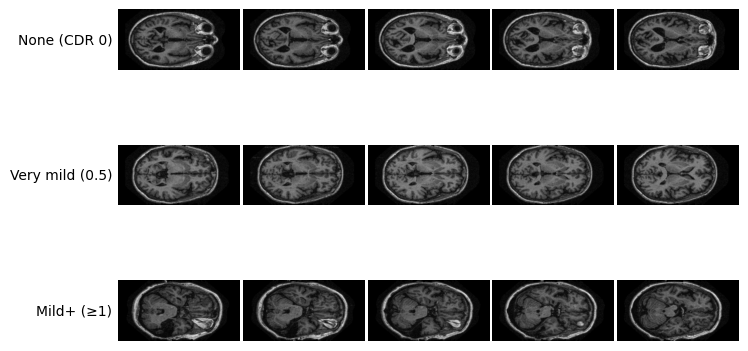

In [ ]:
# Example slices: one participant per class, five of their ten slices.
import matplotlib.pyplot as plt
SHORT = ['None (CDR 0)', 'Very mild (0.5)', 'Mild+ (≥1)']
fig, axes = plt.subplots(3, 5, figsize=(8, 5.2))
for r in range(3):
    person = sorted(slices[(slices.label == r) & (slices.part == 'train')].subject.unique())[0]
    rows = slices[slices.subject == person].sort_values('slice').iloc[::2]
    for c, (_, s) in enumerate(rows.iterrows()):
        axes[r, c].imshow(plt.imread(s.file), cmap='gray')
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        for sp in axes[r, c].spines.values():
            sp.set_visible(False)
    axes[r, 0].set_ylabel(SHORT[r], rotation=0, ha='right', va='center')
fig.subplots_adjust(wspace=0.03, hspace=0.05)
fig.savefig(f'{RESULTS}/figures/oasis1_examples.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{RESULTS}/figures/oasis1_examples.pdf', bbox_inches='tight')
plt.show()

## 3. Class descriptions

Two sets: the original descriptions, used in the same way as the authors' GPT-4 prompts, and a second set that only mentions features visible on these slices (two-class task only).

In [ ]:
# 1) The original descriptions (same as notebook 2), written with an LLM in the
#    style of the BiomedCoOp prompts. For the two-class task, the 'dementia'
#    class gets 25 of the very mild and 25 of the mild descriptions.
ORIGINAL = {
    "no dementia": [
        "An axial brain MRI showing full, rounded hippocampi with narrow temporal horns, indicating no dementia.",
        "A brain MRI slice with tightly packed cortical gyri and thin sulci across both hemispheres, consistent with no dementia.",
        "An MRI of the brain with small, slit-like lateral ventricles and no enlargement of the temporal horns, suggesting no dementia.",
        "An axial MRI showing a thick, well-preserved cortical ribbon in the temporal and parietal lobes, indicating no dementia.",
        "A brain MRI with a narrow Sylvian fissure and no widening of the space around the medial temporal lobe, consistent with no dementia.",
        "An MRI slice of the brain where the medial temporal lobe fills its space with little surrounding cerebrospinal fluid, suggesting no dementia.",
        "An axial brain MRI with symmetrical hemispheres, normal-sized ventricles and no visible tissue loss, indicating no dementia.",
        "A brain MRI showing only mild, age-appropriate sulcal widening with preserved hippocampal volume, consistent with no dementia.",
        "An MRI of the brain in which the gray matter is evenly thick and the white matter appears full and uniform, suggesting no dementia.",
        "An axial MRI slice showing a compact third ventricle and closely opposed frontal and temporal gyri, indicating no dementia.",
        "A brain MRI with clearly defined hippocampal heads and no dark fluid gap between the hippocampus and the brainstem, consistent with no dementia.",
        "An MRI of the brain showing narrow cortical sulci over the parietal lobes and no posterior atrophy, suggesting no dementia.",
        "An axial brain MRI in which the brain tissue fills most of the skull with only a thin rim of surrounding fluid, indicating no dementia.",
        "A brain MRI slice with small frontal horns of the lateral ventricles and a normal caudate outline, consistent with no dementia.",
        "An MRI showing intact entorhinal and parahippocampal cortex with no thinning of the medial temporal lobe, suggesting no dementia.",
        "An axial brain MRI with sharply defined gray-white matter boundaries and no areas of cortical thinning, indicating no dementia.",
        "A brain MRI with temporal lobes of normal size and a narrow temporal horn on both sides, consistent with no dementia.",
        "An MRI of the brain showing a normal width of the interhemispheric fissure and full frontal lobes, suggesting no dementia.",
        "An axial MRI slice in which the ventricles are small relative to the surrounding brain tissue, indicating no dementia.",
        "A brain MRI showing a normal precuneus and posterior cingulate region with tight sulci, consistent with no dementia.",
        "An MRI of the brain with no hippocampal shrinkage and a choroidal fissure that is barely visible, suggesting no dementia.",
        "An axial brain MRI showing healthy brain volume for age, with no ventricular or sulcal enlargement, indicating no dementia.",
        "A brain MRI slice with evenly spaced gyri and no deepening of the sulci in the temporal or parietal cortex, consistent with no dementia.",
        "An MRI of the brain with an intact insular cortex and a closed Sylvian fissure, suggesting no dementia.",
        "An axial MRI showing symmetrical medial temporal lobes of normal height on both sides, indicating no dementia.",
        "A brain MRI with a smooth, normal ventricular outline and no rounding or ballooning of the ventricles, consistent with no dementia.",
        "An MRI slice of the brain in which the cortex appears full in all lobes, with no regional pattern of tissue loss, suggesting no dementia.",
        "An axial brain MRI showing a small amount of cerebrospinal fluid over the convexities and in the basal cisterns, indicating no dementia.",
        "A brain MRI with well-preserved white matter volume and a normally thick corpus callosum, consistent with no dementia.",
        "An MRI of the brain showing hippocampi of normal shape with a clear internal structure, suggesting no dementia.",
        "An axial MRI slice with narrow sulci and plump gyri in the frontal, temporal and parietal lobes, indicating no dementia.",
        "A brain MRI showing no widening of the perihippocampal fissures and no enlargement of the temporal horns, consistent with no dementia.",
        "An MRI of the brain with a normal brain-to-fluid ratio and no global loss of brain volume, suggesting no dementia.",
        "An axial brain MRI in which the lateral ventricles are narrow and do not extend into enlarged temporal horns, indicating no dementia.",
        "A brain MRI slice showing a normal thickness of the parietal cortex with no posterior predominant atrophy, consistent with no dementia.",
        "An MRI showing no visible shrinkage of the medial temporal lobe and preserved amygdala volume, suggesting no dementia.",
        "An axial MRI of the brain with compact ventricles, thin sulci and a normal Sylvian fissure, indicating no dementia.",
        "A brain MRI showing the typical brain shape of a healthy older adult with only minimal sulcal prominence, consistent with no dementia.",
        "An MRI slice of the brain with intact cortical folding and no flattening or thinning of the gyri, suggesting no dementia.",
        "An axial brain MRI with symmetrical, normal-sized ventricles and no asymmetric temporal atrophy, indicating no dementia.",
        "A brain MRI showing normal hippocampal width and a well-defined collateral sulcus, consistent with no dementia.",
        "An MRI of the brain in which the space between the brain surface and the skull is narrow, suggesting no dementia.",
        "An axial MRI slice showing a normal-sized third ventricle and closely spaced thalami, indicating no dementia.",
        "A brain MRI with uniform gray matter signal and no regions of reduced cortical volume, consistent with no dementia.",
        "An MRI of the brain showing preserved temporal lobe volume with no widening of the temporal sulci, suggesting no dementia.",
        "An axial brain MRI in which the frontal horns are small and the caudate heads keep their normal convex shape, indicating no dementia.",
        "A brain MRI slice with no medial temporal lobe atrophy on visual rating and normal ventricular size, consistent with no dementia.",
        "An MRI showing full cerebral hemispheres with a thin layer of fluid in the sulci, suggesting no dementia.",
        "An axial brain MRI with normal volume in the hippocampus, entorhinal cortex and temporal neocortex, indicating no dementia.",
        "A brain MRI showing a healthy, age-appropriate brain with no pattern of atrophy typical of Alzheimer's disease, consistent with no dementia."
    ],
    "very mild dementia": [
        "An axial brain MRI showing slight narrowing of the hippocampi with early widening of the temporal horns, indicating very mild dementia.",
        "A brain MRI slice with subtle thinning of the medial temporal lobe and a slightly more visible choroidal fissure, consistent with very mild dementia.",
        "An MRI of the brain showing mildly widened sulci in the temporal lobes while the rest of the cortex looks largely preserved, suggesting very mild dementia.",
        "An axial MRI with a small increase in cerebrospinal fluid around the hippocampi compared with a healthy brain, indicating very mild dementia.",
        "A brain MRI showing early, subtle volume loss in the entorhinal cortex with otherwise near-normal brain structure, consistent with very mild dementia.",
        "An MRI slice of the brain with slightly enlarged lateral ventricles and minimal sulcal widening, suggesting very mild dementia.",
        "An axial brain MRI showing a faint widening of the Sylvian fissures and the temporal sulci, indicating very mild dementia.",
        "A brain MRI with mild hippocampal volume loss that is only just visible on an axial slice, consistent with very mild dementia.",
        "An MRI of the brain showing early thinning of the parietal cortex with slightly deeper sulci over the precuneus, suggesting very mild dementia.",
        "An axial MRI slice in which the temporal horns are slightly larger than expected for age, indicating very mild dementia.",
        "A brain MRI showing borderline medial temporal lobe atrophy with a small dark gap next to the hippocampus, consistent with very mild dementia.",
        "An MRI of the brain with mild, diffuse sulcal prominence slightly beyond what is typical for age, suggesting very mild dementia.",
        "An axial brain MRI showing early asymmetric shrinkage of one hippocampus with the other still near normal, indicating very mild dementia.",
        "A brain MRI slice with slightly rounded frontal horns and a marginally widened third ventricle, consistent with very mild dementia.",
        "An MRI showing subtle loss of temporal lobe volume, with gyri that look slightly thinner than in a healthy brain, suggesting very mild dementia.",
        "An axial brain MRI with a thin but visible rim of extra fluid along the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI showing a mild increase in the size of the lateral ventricles while the cortex remains mostly intact, consistent with very mild dementia.",
        "An MRI of the brain in which the hippocampal head appears slightly flattened, suggesting very mild dementia.",
        "An axial MRI slice showing early widening of the posterior cingulate and parietal sulci, indicating very mild dementia.",
        "A brain MRI with slight enlargement of the perihippocampal fissures and the temporal horn, consistent with very mild dementia.",
        "An MRI of the brain showing a small reduction in overall brain volume relative to the skull, suggesting very mild dementia.",
        "An axial brain MRI with faint cortical thinning in the temporal and parietal lobes and preserved frontal lobes, indicating very mild dementia.",
        "A brain MRI slice in which the medial temporal lobe looks slightly smaller than normal on visual rating, consistent with very mild dementia.",
        "An MRI showing mild opening of the Sylvian fissure and slight thinning of the insular cortex, suggesting very mild dementia.",
        "An axial MRI of the brain showing early ventricular enlargement with the temporal horns starting to open up, indicating very mild dementia.",
        "A brain MRI with gyri that are slightly narrower and sulci that are slightly wider than expected for age, consistent with very mild dementia.",
        "An MRI of the brain showing subtle volume loss in the parahippocampal gyrus with an otherwise normal-looking slice, suggesting very mild dementia.",
        "An axial brain MRI with a mild increase of fluid in the basal cisterns around the medial temporal lobes, indicating very mild dementia.",
        "A brain MRI slice showing early hippocampal atrophy that is easy to miss without comparison to a healthy scan, consistent with very mild dementia.",
        "An MRI showing slightly deepened temporal sulci and a mildly prominent collateral sulcus, suggesting very mild dementia.",
        "An axial brain MRI in which the lateral ventricles are just above normal size for an older adult, indicating very mild dementia.",
        "A brain MRI showing a subtle pattern of temporoparietal volume loss with preserved occipital lobes, consistent with very mild dementia.",
        "An MRI of the brain with slight thinning of the cortical ribbon in the medial temporal region, suggesting very mild dementia.",
        "An axial MRI slice showing a narrow but visible fluid space separating the hippocampus from surrounding structures, indicating very mild dementia.",
        "A brain MRI with mild widening of the interhemispheric fissure and slight frontal sulcal prominence, consistent with very mild dementia.",
        "An MRI of the brain showing early shrinkage of the amygdala and hippocampus with mild temporal horn dilation, suggesting very mild dementia.",
        "An axial brain MRI with slightly more cerebrospinal fluid over the convexities than in a healthy brain of the same age, indicating very mild dementia.",
        "A brain MRI slice showing minimal but definite hippocampal volume loss on both sides, consistent with very mild dementia.",
        "An MRI showing a slightly enlarged choroidal fissure and early thinning of the medial temporal cortex, suggesting very mild dementia.",
        "An axial MRI of the brain with mild ventricular rounding and slight widening of the cortical sulci, indicating very mild dementia.",
        "A brain MRI showing early posterior cortical thinning around the precuneus with near-normal hippocampi, consistent with very mild dementia.",
        "An MRI of the brain in which the temporal lobes look marginally smaller than the frontal lobes would suggest, suggesting very mild dementia.",
        "An axial brain MRI showing faint widening of the sulci between the temporal gyri, indicating very mild dementia.",
        "A brain MRI slice with a small increase in temporal horn width and slight hippocampal flattening, consistent with very mild dementia.",
        "An MRI showing early, mild global atrophy with slightly enlarged ventricles and sulci, suggesting very mild dementia.",
        "An axial MRI of the brain with subtle entorhinal and hippocampal volume loss and a preserved cortex elsewhere, indicating very mild dementia.",
        "A brain MRI showing mild medial temporal lobe atrophy, rated as just above normal on a visual scale, consistent with very mild dementia.",
        "An MRI of the brain with slightly widened parietal and temporal sulci and a mildly open Sylvian fissure, suggesting very mild dementia.",
        "An axial brain MRI in which the brain still looks largely normal apart from early hippocampal shrinkage, indicating very mild dementia.",
        "A brain MRI showing the earliest visible stage of the atrophy pattern of Alzheimer's disease, centred on the medial temporal lobe, consistent with very mild dementia."
    ],
    "mild dementia": [
        "An axial brain MRI showing clear shrinkage of both hippocampi with widened temporal horns, indicating mild dementia.",
        "A brain MRI slice with obvious medial temporal lobe atrophy and an enlarged choroidal fissure, consistent with mild dementia.",
        "An MRI of the brain showing moderately enlarged lateral ventricles and widened cortical sulci, suggesting mild dementia.",
        "An axial MRI with a clear gap of cerebrospinal fluid around the shrunken hippocampi, indicating mild dementia.",
        "A brain MRI showing visible thinning of the temporal and parietal cortex with deepened sulci, consistent with mild dementia.",
        "An MRI slice of the brain with a widened Sylvian fissure and visible loss of temporal lobe volume, suggesting mild dementia.",
        "An axial brain MRI showing enlarged temporal horns that are clearly visible next to atrophic hippocampi, indicating mild dementia.",
        "A brain MRI with definite hippocampal atrophy and moderate widening of the sulci over both hemispheres, consistent with mild dementia.",
        "An MRI of the brain showing clear parietal atrophy with widened sulci around the precuneus and posterior cingulate, suggesting mild dementia.",
        "An axial MRI slice in which the lateral ventricles are noticeably larger than normal for age, indicating mild dementia.",
        "A brain MRI showing medial temporal lobe atrophy that is easy to see on an axial slice, with thin parahippocampal gyri, consistent with mild dementia.",
        "An MRI of the brain with moderate global atrophy, enlarged ventricles and more fluid between the gyri, suggesting mild dementia.",
        "An axial brain MRI showing shrunken temporal lobes with widened temporal sulci on both sides, indicating mild dementia.",
        "A brain MRI slice with enlarged frontal horns and a widened third ventricle, consistent with mild dementia.",
        "An MRI showing clear volume loss in the hippocampus, amygdala and entorhinal cortex, suggesting mild dementia.",
        "An axial brain MRI with thin, narrow gyri separated by wide sulci in the temporal and parietal lobes, indicating mild dementia.",
        "A brain MRI showing a temporoparietal pattern of atrophy with relatively preserved occipital and sensorimotor cortex, consistent with mild dementia.",
        "An MRI of the brain in which the hippocampal head is visibly small and surrounded by enlarged fluid spaces, suggesting mild dementia.",
        "An axial MRI slice showing a widened interhemispheric fissure and frontal sulcal enlargement in addition to temporal atrophy, indicating mild dementia.",
        "A brain MRI with clearly dilated temporal horns and widened perihippocampal fissures, consistent with mild dementia.",
        "An MRI of the brain showing a reduced brain-to-skull ratio with more cerebrospinal fluid over the brain surface, suggesting mild dementia.",
        "An axial brain MRI with moderate thinning of the cortical ribbon in the temporal lobes, indicating mild dementia.",
        "A brain MRI slice in which the medial temporal lobe atrophy is rated as moderate on a visual scale, consistent with mild dementia.",
        "An MRI showing a clearly open Sylvian fissure and thinning of the insula, suggesting mild dementia.",
        "An axial MRI of the brain with rounded, enlarged lateral ventricles and visible periventricular tissue loss, indicating mild dementia.",
        "A brain MRI showing wider sulci and thinner gyri than in very mild disease, with clear hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain showing atrophy of the parahippocampal gyrus with a prominent collateral sulcus, suggesting mild dementia.",
        "An axial brain MRI with enlarged basal cisterns around atrophic medial temporal lobes, indicating mild dementia.",
        "A brain MRI slice showing hippocampal atrophy on both sides that is clearly visible without comparison images, consistent with mild dementia.",
        "An MRI showing deepened and widened sulci between the temporal gyri with reduced temporal lobe bulk, suggesting mild dementia.",
        "An axial brain MRI in which the lateral ventricles take up a noticeably larger part of the slice, indicating mild dementia.",
        "A brain MRI showing moderate posterior cortical atrophy around the precuneus and parietal lobes, consistent with mild dementia.",
        "An MRI of the brain with clear loss of cortical thickness in the medial temporal region and an enlarged temporal horn, suggesting mild dementia.",
        "An axial MRI slice showing a wide fluid space separating the shrunken hippocampus from the brainstem, indicating mild dementia.",
        "A brain MRI with moderate frontal and temporal sulcal widening and a slightly thinned corpus callosum, consistent with mild dementia.",
        "An MRI of the brain showing visible shrinkage of the amygdala and hippocampus with dilated temporal horns, suggesting mild dementia.",
        "An axial brain MRI with a clear rim of cerebrospinal fluid over the convexities and widened sulci, indicating mild dementia.",
        "A brain MRI slice showing definite bilateral hippocampal volume loss, more marked than in very mild disease, consistent with mild dementia.",
        "An MRI showing an enlarged choroidal fissure and clear thinning of the medial temporal cortex, suggesting mild dementia.",
        "An axial MRI of the brain with enlarged, rounded ventricles and moderately widened cortical sulci, indicating mild dementia.",
        "A brain MRI showing clear posterior cingulate and parietal atrophy together with hippocampal shrinkage, consistent with mild dementia.",
        "An MRI of the brain in which the temporal lobes look clearly smaller than in a healthy older adult, suggesting mild dementia.",
        "An axial brain MRI showing widened sulci between thin temporal gyri and an open Sylvian fissure, indicating mild dementia.",
        "A brain MRI slice with enlarged temporal horns and flattened, atrophic hippocampi, consistent with mild dementia.",
        "An MRI showing moderate global atrophy with enlarged ventricles and sulci beyond what is expected for age, suggesting mild dementia.",
        "An axial MRI of the brain with clear entorhinal and hippocampal volume loss and early thinning of the neocortex, indicating mild dementia.",
        "A brain MRI showing moderate medial temporal lobe atrophy on visual rating together with ventricular enlargement, consistent with mild dementia.",
        "An MRI of the brain with widened parietal and temporal sulci and a clearly enlarged Sylvian fissure, suggesting mild dementia.",
        "An axial brain MRI in which the atrophy of the medial temporal lobes has spread to the temporal and parietal cortex, indicating mild dementia.",
        "A brain MRI showing a clear Alzheimer's disease pattern of atrophy in the hippocampus and temporoparietal cortex, consistent with mild dementia."
    ]
}
ORIGINAL['dementia'] = ORIGINAL['very mild dementia'][:25] + ORIGINAL['mild dementia'][:25]

# 2) Descriptions matched to the visible anatomy (two-class task only). Each
#    class gets 10 features that can be seen on a mid-level axial slice,
#    written into 5 sentence frames (50 sentences). The two lists describe the
#    same structures, so the classes differ only in the direction of the change.
VISIBLE_FEATURES = {
    'no dementia': [
        'small, narrow lateral ventricles', 'thin, tightly packed cortical sulci',
        'only a thin rim of fluid between the brain and the skull', 'a thick, even cortical ribbon',
        'a narrow interhemispheric fissure', 'full, rounded gyri',
        'brain tissue that fills most of the skull', 'a narrow Sylvian fissure',
        'full, uniform white matter', 'a small, slit-like third ventricle'],
    'dementia': [
        'enlarged, widened lateral ventricles', 'wide, deep cortical sulci',
        'a wide rim of fluid between the brain and the skull', 'a thinned cortical ribbon',
        'a widened interhemispheric fissure', 'shrunken, narrow gyri',
        'brain tissue that has pulled away from the skull', 'a widened Sylvian fissure',
        'reduced white matter volume', 'an enlarged third ventricle'],
}
FRAMES = ['An axial brain MRI slice showing {f}, indicating {c}.',
          'A T1-weighted brain MRI with {f}, consistent with {c}.',
          'A brain MRI scan that shows {f}, suggesting {c}.',
          'An axial MRI of the brain with {f}, as seen in a person with {c}.',
          'A grayscale axial brain MRI image showing {f}, pointing to {c}.']
VISIBLE = {c: [fr.format(f=f, c=c) for f in feats for fr in FRAMES] for c, feats in VISIBLE_FEATURES.items()}

# 3) Detailed descriptions without negation (two-class task only). The healthy
#    class is described only by what is there (full, compact, thick, preserved),
#    never as the absence of disease, and uses no disease words. Vision-language
#    models are known to handle negation poorly (Alhamoud et al., 2025), and many
#    of the original healthy descriptions use phrases such as "no hippocampal shrinkage".
DETAILED = {
    "no dementia": [
        "An axial T1-weighted MRI slice with compact, slit-like lateral ventricles and tightly packed gyri, consistent with no dementia.",
        "A brain MRI in which the cortical gray matter forms a thick, continuous ribbon around both hemispheres, typical of no dementia.",
        "An axial brain MRI showing plump, rounded gyri pressed closely together with only hairline sulci between them, indicating no dementia.",
        "A mid-level axial MRI where the brain fills the skull almost completely, leaving a very thin layer of cerebrospinal fluid at the surface, suggesting no dementia.",
        "An MRI slice showing a narrow interhemispheric fissure with the two frontal lobes lying close together, consistent with no dementia.",
        "A T1-weighted axial MRI with bright, full white matter and a sharp boundary between gray and white matter, typical of no dementia.",
        "An axial brain MRI in which the bodies of the lateral ventricles are thin and narrow compared with the surrounding white matter, indicating no dementia.",
        "A brain MRI slice with a small, slit-shaped third ventricle between closely spaced thalami, suggesting no dementia.",
        "An axial MRI showing well-preserved frontal and parietal lobes with dense, regular cortical folding, consistent with no dementia.",
        "A brain MRI of an older adult with healthy brain volume for age and a compact ventricular system, typical of no dementia.",
        "An axial MRI slice in which the Sylvian fissures appear as thin dark lines between full temporal and frontal lobes, indicating no dementia.",
        "A T1-weighted MRI with small frontal horns and caudate heads that keep their rounded outline, suggesting no dementia.",
        "An axial brain MRI showing symmetrical hemispheres with evenly thick cortex in every lobe, consistent with no dementia.",
        "A mid-brain axial MRI where gray matter, white matter and fluid spaces have the proportions of a healthy older brain, typical of no dementia.",
        "An MRI slice with dark cerebrospinal fluid confined to small ventricles and thin sulci, indicating no dementia.",
        "An axial MRI showing a full, thick corpus callosum bridging the hemispheres, suggesting no dementia.",
        "A brain MRI in which the parietal cortex and precuneus are full with tightly closed sulci, consistent with no dementia.",
        "An axial T1-weighted slice with a large area of white matter around small, narrow ventricles, typical of no dementia.",
        "A brain MRI showing a smooth, compact outline of the lateral ventricles with sharp, thin edges, indicating no dementia.",
        "An axial MRI of an older adult with preserved cortical thickness in the frontal, temporal and parietal lobes, suggesting no dementia.",
        "A brain MRI slice in which the brain surface lies close to the inner skull along its whole length, consistent with no dementia.",
        "An axial MRI showing healthy, firm-looking gyri with a uniform gray-matter signal, typical of no dementia.",
        "A T1-weighted brain MRI with compact ventricles taking up only a small fraction of the slice, indicating no dementia.",
        "An axial MRI with narrow sulci over the convexities and a thin interhemispheric fissure, suggesting no dementia.",
        "A brain MRI slice showing full insular cortex and closed, narrow Sylvian fissures, consistent with no dementia.",
        "An axial brain MRI in which the white matter looks dense and uniform from the ventricles to the cortex, typical of no dementia.",
        "A mid-level axial MRI with small, symmetrical frontal and occipital horns, indicating no dementia.",
        "An MRI showing a well-preserved brain with a high ratio of brain tissue to cerebrospinal fluid, suggesting no dementia.",
        "An axial T1-weighted slice with full temporal lobes and narrow temporal sulci, consistent with no dementia.",
        "A brain MRI where the cortical ribbon is clearly visible and evenly thick around every gyrus, typical of no dementia.",
        "An axial MRI showing tightly folded cortex with gyri that touch each other across thin sulci, indicating no dementia.",
        "A brain MRI slice of a healthy older person with small ventricles and full hemispheres, suggesting no dementia.",
        "An axial MRI in which the space between the two hemispheres is a thin dark line, consistent with no dementia.",
        "A T1-weighted brain MRI with healthy, full frontal lobes and narrow frontal sulci, typical of no dementia.",
        "An axial MRI slice showing a compact ventricular system centred in plentiful white matter, indicating no dementia.",
        "A brain MRI where the outer brain surface is smooth and full, with only a thin rim of fluid beneath the skull, suggesting no dementia.",
        "An axial MRI showing a dense, well-preserved cortex in the posterior cingulate and parietal regions, consistent with no dementia.",
        "A brain MRI slice with full, bright white matter and thin, narrow ventricles, typical of no dementia.",
        "An axial T1-weighted MRI in which the brain looks full and compact for an older adult, indicating no dementia.",
        "A brain MRI showing closely spaced gyri and a thick, even cortical ribbon, suggesting no dementia.",
        "An axial MRI slice with small lateral ventricles and a narrow third ventricle, consistent with no dementia.",
        "A mid-level axial brain MRI with full hemispheres that leave little room for surface fluid, typical of no dementia.",
        "An MRI showing healthy brain structure with preserved volume in all lobes, indicating no dementia.",
        "An axial T1-weighted slice with crisp gray-white matter contrast and full gyri, suggesting no dementia.",
        "A brain MRI in which the ventricles and sulci are small and the brain tissue is plentiful, consistent with no dementia.",
        "An axial MRI showing a compact brain with narrow fissures and tightly packed cortical folds, typical of no dementia.",
        "A brain MRI slice of an older adult whose brain volume is well preserved for age, indicating no dementia.",
        "An axial MRI with thick cortex, full white matter and slender ventricles, suggesting no dementia.",
        "A T1-weighted brain MRI showing healthy proportions of brain and fluid on a mid-level axial slice, consistent with no dementia.",
        "An axial brain MRI with a full, healthy-looking brain and compact fluid spaces throughout the slice, typical of no dementia."
    ],
    "dementia": [
        "An axial T1-weighted MRI slice with clearly enlarged lateral ventricles and widened sulci, consistent with dementia.",
        "A brain MRI in which the cortical ribbon is thin and the gyri look shrunken and narrow, typical of dementia.",
        "An axial brain MRI showing deep, widened sulci separating thin gyri over both hemispheres, indicating dementia.",
        "A mid-level axial MRI with a wide rim of cerebrospinal fluid between the shrunken brain and the skull, suggesting dementia.",
        "An MRI slice showing a widened interhemispheric fissure with the frontal lobes pulled apart, consistent with dementia.",
        "A T1-weighted axial MRI with reduced white matter volume and a blurred gray-white matter boundary, typical of dementia.",
        "An axial brain MRI in which the bodies of the lateral ventricles are broad and ballooned, indicating dementia.",
        "A brain MRI slice with an enlarged, rounded third ventricle between thinned thalami, suggesting dementia.",
        "An axial MRI showing atrophy of the frontal and parietal lobes with open, gaping sulci, consistent with dementia.",
        "A brain MRI of an older adult with brain volume clearly reduced for age and an enlarged ventricular system, typical of dementia.",
        "An axial MRI slice in which the Sylvian fissures are wide and filled with dark fluid, indicating dementia.",
        "A T1-weighted MRI with enlarged frontal horns and flattened caudate heads, suggesting dementia.",
        "An axial brain MRI showing global cortical thinning in every lobe, consistent with dementia.",
        "A mid-brain axial MRI where fluid spaces take up a large share of the slice compared with brain tissue, typical of dementia.",
        "An MRI slice with dark cerebrospinal fluid filling large ventricles and wide sulci, indicating dementia.",
        "An axial MRI showing a thinned corpus callosum between enlarged ventricles, suggesting dementia.",
        "A brain MRI in which the parietal cortex and precuneus are thin with widened sulci, consistent with dementia.",
        "An axial T1-weighted slice with shrunken white matter around large, dilated ventricles, typical of dementia.",
        "A brain MRI showing a broad, rounded outline of the lateral ventricles pushing into the white matter, indicating dementia.",
        "An axial MRI of an older adult with marked loss of cortical thickness in the temporal and parietal lobes, suggesting dementia.",
        "A brain MRI slice in which the brain surface has pulled away from the inner skull, leaving a wide gap of fluid, consistent with dementia.",
        "An axial MRI showing thin, shrunken gyri with widened spaces between them, typical of dementia.",
        "A T1-weighted brain MRI with ventricles taking up a large part of the slice, indicating dementia.",
        "An axial MRI with wide sulci over the convexities and an open interhemispheric fissure, suggesting dementia.",
        "A brain MRI slice showing thinned insular cortex and widely open Sylvian fissures, consistent with dementia.",
        "An axial brain MRI in which the white matter looks reduced and thin between the ventricles and the cortex, typical of dementia.",
        "A mid-level axial MRI with enlarged, rounded frontal and occipital horns, indicating dementia.",
        "An MRI showing marked brain atrophy with a low ratio of brain tissue to cerebrospinal fluid, suggesting dementia.",
        "An axial T1-weighted slice with shrunken temporal lobes and widened temporal sulci, consistent with dementia.",
        "A brain MRI where the cortical ribbon is thin and uneven, with deep sulci between the gyri, typical of dementia.",
        "An axial MRI showing loosely folded cortex with wide, fluid-filled gaps between the gyri, indicating dementia.",
        "A brain MRI slice of an older person with large ventricles and shrunken hemispheres, suggesting dementia.",
        "An axial MRI in which the space between the two hemispheres is a wide band of dark fluid, consistent with dementia.",
        "A T1-weighted brain MRI with atrophied frontal lobes and widened frontal sulci, typical of dementia.",
        "An axial MRI slice showing a dilated ventricular system surrounded by reduced white matter, indicating dementia.",
        "A brain MRI where the outer brain surface is uneven and shrunken, with a thick layer of fluid beneath the skull, suggesting dementia.",
        "An axial MRI showing thinning of the cortex in the posterior cingulate and parietal regions, consistent with dementia.",
        "A brain MRI slice with reduced white matter and broad, enlarged ventricles, typical of dementia.",
        "An axial T1-weighted MRI in which the brain looks shrunken and loose for an older adult, indicating dementia.",
        "A brain MRI showing widely spaced gyri and a thin cortical ribbon, suggesting dementia.",
        "An axial MRI slice with enlarged lateral ventricles and a widened third ventricle, consistent with dementia.",
        "A mid-level axial brain MRI with shrunken hemispheres surrounded by a wide layer of surface fluid, typical of dementia.",
        "An MRI showing diffuse brain atrophy with volume loss across the temporal and parietal lobes, indicating dementia.",
        "An axial T1-weighted slice with weak gray-white matter contrast and thin gyri, suggesting dementia.",
        "A brain MRI in which the ventricles and sulci are large and the brain tissue is reduced, consistent with dementia.",
        "An axial MRI showing a shrunken brain with wide fissures and loosely spaced cortical folds, typical of dementia.",
        "A brain MRI slice of an older adult whose brain volume is clearly reduced for age, indicating dementia.",
        "An axial MRI with thin cortex, reduced white matter and broad ventricles, suggesting dementia.",
        "A T1-weighted brain MRI showing a high proportion of fluid to brain on a mid-level axial slice, consistent with dementia.",
        "An axial brain MRI with a shrunken, atrophic brain and enlarged fluid spaces throughout the slice, typical of dementia."
    ]
}
banned = ['atroph', 'shrunk', 'enlarg', 'widen', 'loss', 'reduced', 'alzheimer', ' no ', 'without']
for s in DETAILED['no dementia']:
    assert not any(b in s[:s.rfind('no dementia')].lower() for b in banned), s

os.makedirs('/content/alz_ext', exist_ok=True)
# 4) Medial temporal lobe descriptions (two-class task only). AD atrophy starts
#    in the hippocampus and the medial temporal lobe, which the visual MTA scale
#    rates by the hippocampus, the temporal horn and the choroid fissure. Same
#    10 features x 5 frames format as the visible-anatomy set, and again the
#    healthy class is described by what is there, without negation.
MTL_FEATURES = {
    'no dementia': [
        'full, rounded hippocampi on both sides', 'narrow, slit-like temporal horns',
        'a barely visible choroid fissure', 'full medial temporal lobes',
        'tightly packed temporal lobe gyri', 'a full parahippocampal gyrus',
        'small fluid spaces around the hippocampus', 'compact lateral ventricles',
        'thin, closely spaced cortical sulci', 'a thick cortical ribbon in the temporal lobes'],
    'dementia': [
        'shrunken, flattened hippocampi on both sides', 'enlarged, widened temporal horns',
        'a widened choroid fissure', 'atrophied medial temporal lobes',
        'widely spaced temporal lobe gyri', 'a thinned parahippocampal gyrus',
        'large fluid spaces around the hippocampus', 'enlarged lateral ventricles',
        'wide, deep cortical sulci', 'a thinned cortical ribbon in the temporal lobes'],
}
MTL = {c: [fr.format(f=f, c=c) for f in feats for fr in FRAMES] for c, feats in MTL_FEATURES.items()}
for s in MTL['no dementia']:
    assert not any(b in s[:s.rfind('no dementia')].lower() for b in banned), s

for tag, d in [('original', ORIGINAL), ('visible', VISIBLE), ('detailed', DETAILED), ('mtl', MTL)]:
    for name, sents in d.items():
        assert len(set(sents)) == 50 and all(s.rstrip('.').endswith(name) for s in sents), (tag, name)
    json.dump(d, open(f'/content/alz_ext/descriptions_{tag}.json', 'w'), indent=1)
    print(tag, {k: len(v) for k, v in d.items()})
print('\ne.g.', VISIBLE['dementia'][0])

original {'no dementia': 50, 'very mild dementia': 50, 'mild dementia': 50, 'dementia': 50}
visible {'no dementia': 50, 'dementia': 50}
detailed {'no dementia': 50, 'dementia': 50}
mtl {'no dementia': 50, 'dementia': 50}

e.g. An axial brain MRI slice showing enlarged, widened lateral ventricles, indicating dementia.


## 4. Adding the datasets to BiomedCoOp

In [ ]:
%%writefile /content/alz_ext/oasis_ext.py
"""Adds the two OASIS-1 datasets to BiomedCoOp, without changing the authors' files.

OASIS1     three classes (CDR 0 / 0.5 / >= 1)
OASIS1BIN  two classes (CDR 0 / >= 0.5), same participants, images and split
OASIS1BINR the two-class dataset with other class names (see section 9)
"""
import json
import os
import pickle

from dassl.data.datasets import DATASET_REGISTRY, DatasetBase, Datum
from dassl.utils import mkdir_if_missing

from datasets.btmri import BTMRI  # reused for its split reading and few-shot sampling


@DATASET_REGISTRY.register()
class OASIS1(BTMRI):

    folder = 'OASIS1'

    def __init__(self, cfg):
        root = os.path.abspath(os.path.expanduser(cfg.DATASET.ROOT))
        self.dataset_dir = os.path.join(root, self.folder)
        self.image_dir = os.path.join(self.dataset_dir, 'images')
        self.split_path = os.path.join(self.dataset_dir, f'split_{self.folder}.json')
        self.split_fewshot_dir = os.path.join(self.dataset_dir, 'split_fewshot')
        mkdir_if_missing(self.split_fewshot_dir)
        train, val, test = self.read_split(self.split_path, self.image_dir)

        # The K-shot samples are saved once per (K, seed), so every method sees
        # exactly the same labelled images.
        num_shots = cfg.DATASET.NUM_SHOTS
        if num_shots >= 1:
            cache = os.path.join(self.split_fewshot_dir, f'shot_{num_shots}-seed_{cfg.SEED}.pkl')
            if os.path.exists(cache):
                with open(cache, 'rb') as f:
                    data = pickle.load(f)
                train, val = data['train'], data['val']
            else:
                train = self.generate_fewshot_dataset(train, num_shots=num_shots)
                val = self.generate_fewshot_dataset(val, num_shots=min(num_shots, 4))
                with open(cache, 'wb') as f:
                    pickle.dump({'train': train, 'val': val}, f, protocol=pickle.HIGHEST_PROTOCOL)

        train, val, test = self.subsample_classes(train, val, test, subsample=cfg.DATASET.SUBSAMPLE_CLASSES)
        DatasetBase.__init__(self, train_x=train, val=val, test=test)


@DATASET_REGISTRY.register()
class OASIS1BIN(OASIS1):

    folder = 'OASIS1BIN'


@DATASET_REGISTRY.register()
class OASIS1BINR(OASIS1BIN):
    """OASIS1BIN with other class names (same images, split and K-shot samples).
    The names, the descriptions and the folder of slices are read from naming.json."""

    def __init__(self, cfg):
        choice = json.load(open(NAMING))
        self.folder = choice.get('folder', 'OASIS1BIN')   # another set of slices (section 17)
        super().__init__(cfg)
        names = choice['names']
        rename = lambda items: [Datum(impath=d.impath, label=d.label, domain=d.domain,
                                      classname=names[d.label]) for d in items]
        DatasetBase.__init__(self, train_x=rename(self.train_x), val=rename(self.val),
                             test=rename(self.test))


NAMING = '/content/alz_ext/naming.json'


def register_named():
    """Descriptions for the renamed classes: same sentences, only the class name
    at the end changes (e.g. '..., consistent with healthy aging.')."""
    choice = json.load(open(NAMING))
    from trainers import prompt_templates
    prompt_templates.CUSTOM_TEMPLATES['OASIS1BINR'] = 'a photo of a {}.'
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    for old, new in zip(['no dementia', 'dementia'], choice['names']):
        prompt_templates.BIOMEDCOOP_TEMPLATES[new] = [x[:x.rstrip('.').rfind(old)] + new + '.' for x in src[old]]


def register(descriptions_file):
    """Adds the single template and the class descriptions BiomedCoOp looks up by class name."""
    from trainers import prompt_templates
    for name in ('OASIS1', 'OASIS1BIN'):
        prompt_templates.CUSTOM_TEMPLATES[name] = 'a photo of a {}.'
    prompt_templates.BIOMEDCOOP_TEMPLATES.update(json.load(open(descriptions_file)))

Writing /content/alz_ext/oasis_ext.py


In [ ]:
# One small wrapper per set of descriptions: it registers the datasets and the
# descriptions, then runs the authors' train.py unchanged.
WRAPPER_SRC = """\"\"\"Registers the OASIS-1 datasets with the {tag} descriptions, then runs train.py.\"\"\"
import os, runpy, sys
BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{{BIOMEDCOOP}}/Dassl.pytorch']
import oasis_ext
oasis_ext.register('/content/alz_ext/descriptions_{tag}.json')
sys.argv[0] = f'{{BIOMEDCOOP}}/train.py'
runpy.run_path(sys.argv[0], run_name='__main__')
"""
WRAPPER = {}
for tag in ('original', 'visible'):
    WRAPPER[tag] = f'/content/alz_ext/train_oasis_{tag}.py'
    open(WRAPPER[tag], 'w').write(WRAPPER_SRC.format(tag=tag))

# Wrapper for the renamed two-class dataset (section 9).
WRAPPER['named'] = '/content/alz_ext/train_oasis_named.py'
open(WRAPPER['named'], 'w').write("""\"\"\"Registers the renamed two-class dataset, then runs train.py.\"\"\"
import os, runpy, sys
BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']
import oasis_ext
oasis_ext.register_named()
sys.argv[0] = f'{BIOMEDCOOP}/train.py'
runpy.run_path(sys.argv[0], run_name='__main__')
""")
print(WRAPPER)

{'original': '/content/alz_ext/train_oasis_original.py', 'visible': '/content/alz_ext/train_oasis_visible.py', 'named': '/content/alz_ext/train_oasis_named.py'}


In [ ]:
import shutil
# The authors' BTMRI settings for BiomedCoOp (the only brain MRI dataset in
# the paper), and their standard configs for zero-shot and CoOp.
CFG_DIR = '/content/alz_ext/configs'
os.makedirs(CFG_DIR, exist_ok=True)
DATASET_CFG = {}
for name in ('OASIS1', 'OASIS1BIN', 'OASIS1BINR'):
    DATASET_CFG[name] = f'{CFG_DIR}/{name.lower()}.yaml'
    open(DATASET_CFG[name], 'w').write(f'DATASET:\n  NAME: "{name}"\n')
BIOMEDCOOP_CFG = f'{CFG_DIR}/biomedcoop_oasis.yaml'
shutil.copy(f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/btmri.yaml', BIOMEDCOOP_CFG)
ZEROSHOT_CFG = f'{BIOMEDCOOP}/configs/trainers/Zeroshot/vit_b16.yaml'
COOP_CFG = f'{BIOMEDCOOP}/configs/trainers/CoOp/vit_b16.yaml'

BIOMEDCOOP_OPTS = ['TRAINER.BIOMEDCOOP.N_CTX', '4', 'TRAINER.BIOMEDCOOP.CSC', 'False',
                   'TRAINER.BIOMEDCOOP.CLASS_TOKEN_POSITION', 'end']
COOP_OPTS = ['TRAINER.COOP.N_CTX', '4', 'TRAINER.COOP.CSC', 'False',
             'TRAINER.COOP.CLASS_TOKEN_POSITION', 'end']
SEEDS = [1, 2, 3]

# Keep the K-shot samples on Drive, so they stay the same after a Colab reset
# and are part of the records.
for name in ('OASIS1', 'OASIS1BIN'):
    keep = f'{OUTPUTS}/{name}_fewshot_samples'
    os.makedirs(keep, exist_ok=True)
    link = f'{DATA}/{name}/split_fewshot'
    if not os.path.islink(link):
        shutil.rmtree(link, ignore_errors=True)
        os.symlink(keep, link)


def zeroshot(dataset, method, trainer, desc='original'):
    run(trainer, DATASET_CFG[dataset], ZEROSHOT_CFG, f'{OUTPUTS}/{dataset}/{method}',
        eval_only=True, script=WRAPPER[desc])


def sweep(dataset, method, trainer, trainer_cfg, opts, desc='original', shots=SHOTS):
    """All K and seeds for one method. Finished runs are skipped."""
    for k in shots:
        for seed in SEEDS:
            run(trainer, DATASET_CFG[dataset], trainer_cfg,
                f'{OUTPUTS}/{dataset}/{method}/shots_{k}/seed{seed}',
                shots=k, seed=seed, opts=opts, script=WRAPPER[desc])
print('ready')

ready


## 5. Three classes: zero-shot, linear probe and diagnostics

Quick runs (about 5 minutes in total).

In [ ]:
zeroshot('OASIS1', 'zeroshot', 'ZeroshotBiomedCLIP')
zeroshot('OASIS1', 'zeroshot_ensemble', 'ZeroshotBiomedCLIP2')

already done: OASIS1/zeroshot
already done: OASIS1/zeroshot_ensemble


In [ ]:
%%writefile /content/alz_ext/linear_probe_oasis.py
"""Linear probe on frozen BiomedCLIP image features, and the diagnostic
classifiers, for one OASIS-1 dataset.

Usage: python linear_probe_oasis.py DATA OUT DATASET   (DATASET = OASIS1 or OASIS1BIN)

1. Few-shot linear probe on the same K-shot images as BiomedCoOp. C is chosen
   on the few-shot validation images by macro-F1. With so few validation
   images, many values of C tie; ties go to the C closest to 1 (sklearn's
   default), which avoids overly strong regularisation.
2. Diagnostics with the full training set: logistic regression (classes
   weighted equally, C chosen by cross-validated macro-F1) and 1-nearest
   neighbour, on BiomedCLIP features and on raw pixels. They show how much
   information the features hold when labels are not scarce, and 1-NN checks
   whether test images have near-identical images in the training set
   (99.5% on the first dataset).
"""
import os, sys
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

BIOMEDCOOP = '/content/BiomedCoOp'
os.chdir(BIOMEDCOOP)
sys.path[:0] = ['/content/alz_ext', BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']
import oasis_ext  # registers the two datasets
from dassl.config import get_cfg_default
from dassl.data.datasets import build_dataset
from dassl.utils import read_image, set_random_seed
from open_clip.src.open_clip import create_model_from_pretrained  # the authors' copy of open_clip

DATA, OUT, NAME = sys.argv[1], sys.argv[2], sys.argv[3]
SHOTS, SEEDS = [1, 2, 4, 8, 16], [1, 2, 3]
C_GRID = np.logspace(-2, 4, 13)
TAG = 'C by validation macro-F1'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained('hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224')
model.eval().to(device)


def dataset(shots, seed):
    cfg = get_cfg_default()
    cfg.DATASET.NAME, cfg.DATASET.ROOT = NAME, DATA
    cfg.DATASET.NUM_SHOTS, cfg.DATASET.SUBSAMPLE_CLASSES, cfg.SEED = shots, 'all', seed
    set_random_seed(seed)
    return build_dataset(cfg)


@torch.no_grad()
def features(items):
    feats = []
    for i in range(0, len(items), 128):
        x = torch.stack([preprocess(read_image(it.impath)) for it in items[i:i + 128]]).to(device)
        feats.append(torch.nn.functional.normalize(model.encode_image(x), dim=-1).cpu())
    return torch.cat(feats).numpy(), np.array([it.label for it in items])


def pick_c(x_tr, y_tr, x_val, y_val):
    best = None
    for c in C_GRID:
        pred = LogisticRegression(C=c, max_iter=5000).fit(x_tr, y_tr).predict(x_val)
        key = (round(f1_score(y_val, pred, average='macro'), 6), -abs(np.log10(c)))
        if best is None or key > best[0]:
            best = (key, c)
    return best[1]


def write(out, y_true, pred, names, header):
    acc = 100 * (pred == y_true).mean()
    f1 = 100 * f1_score(y_true, pred, average='macro')
    lines = [header, '=> result', f'* accuracy: {acc:.2f}%', f'* macro_f1: {f1:.2f}%', '=> per-class result']
    for c, name in enumerate(names):
        m = y_true == c
        lines.append(f'* class: {c} ({name})\ttotal: {m.sum()}\tcorrect: {(pred[m] == c).sum()}\t'
                     f'acc: {100 * (pred[m] == c).mean():.2f}%')
    os.makedirs(out, exist_ok=True)
    open(f'{out}/log.txt', 'w').write('\n'.join(lines) + '\n')
    torch.save(confusion_matrix(y_true, pred, labels=range(len(names)), normalize='true'), f'{out}/cmat.pt')
    print(f'{header}: accuracy {acc:.2f}%  macro-F1 {f1:.2f}%')


full = dataset(-1, 1)
names = full.classnames
x_test, y_test = features(full.test)

# 1. Few-shot linear probe (runs already done with this rule are skipped)
for k in SHOTS:
    for seed in SEEDS:
        out = f'{OUT}/linear_probe/shots_{k}/seed{seed}'
        if os.path.exists(f'{out}/log.txt') and TAG in open(f'{out}/log.txt').read():
            continue
        ds = dataset(k, seed)
        x_tr, y_tr = features(ds.train_x)
        x_val, y_val = features(ds.val)
        c = pick_c(x_tr, y_tr, x_val, y_val)
        pred = LogisticRegression(C=c, max_iter=5000).fit(x_tr, y_tr).predict(x_test)
        write(out, y_test, pred, names, f'Linear probe K={k} seed={seed}, C = {c:g} ({TAG})')

# 2. Diagnostics with the full training set
DIAG_OUT = OUT + '_diagnostics_balanced'   # kept apart from the method folders
if not os.path.exists(f'{DIAG_OUT}/raw_pixels_1nn/log.txt'):
    x_full, y_full = features(full.train_x)
    px = lambda items: np.stack([np.asarray(read_image(it.impath).convert('L').resize((64, 64)),
                                            dtype=np.float32).ravel() / 255 for it in items])
    scaler = StandardScaler().fit(px(full.train_x))
    p_train, p_test = scaler.transform(px(full.train_x)), scaler.transform(px(full.test))
    for name, (xtr, xte) in {'biomedclip': (x_full, x_test), 'raw_pixels': (p_train, p_test)}.items():
        lr = LogisticRegressionCV(Cs=8, max_iter=3000, n_jobs=-1, class_weight='balanced',
                                  scoring='f1_macro').fit(xtr, y_full)
        write(f'{DIAG_OUT}/{name}_logreg_full', y_test, lr.predict(xte), names, f'{name}, logistic regression, full training set')
        nn = KNeighborsClassifier(n_neighbors=1).fit(xtr, y_full)
        write(f'{DIAG_OUT}/{name}_1nn', y_test, nn.predict(xte), names, f'{name}, 1-nearest neighbour, full training set')
else:
    print('diagnostics already done')

Writing /content/alz_ext/linear_probe_oasis.py


In [ ]:
!python /content/alz_ext/linear_probe_oasis.py {DATA} {OUTPUTS}/OASIS1 OASIS1 2>&1 | grep -E "Linear probe|full training set|already done|Error"

diagnostics already done


## 6. Two classes: zero-shot, linear probe and diagnostics

Zero-shot with one template, with the original descriptions, and with the visible-anatomy descriptions. Then the same linear probe and diagnostics as for three classes.

In [ ]:
zeroshot('OASIS1BIN', 'zeroshot', 'ZeroshotBiomedCLIP')
zeroshot('OASIS1BIN', 'zeroshot_ensemble', 'ZeroshotBiomedCLIP2')
zeroshot('OASIS1BIN', 'zeroshot_ensemble_visible', 'ZeroshotBiomedCLIP2', desc='visible')

already done: OASIS1BIN/zeroshot
already done: OASIS1BIN/zeroshot_ensemble
already done: OASIS1BIN/zeroshot_ensemble_visible


In [ ]:
!python /content/alz_ext/linear_probe_oasis.py {DATA} {OUTPUTS}/OASIS1BIN OASIS1BIN 2>&1 | grep -E "Linear probe|full training set|already done|Error"

diagnostics already done


## 7. Three classes: BiomedCoOp (authors' settings)

 Finished runs are read from Drive and skipped.

In [ ]:
sweep('OASIS1', 'biomedcoop', 'BiomedCoOp_BiomedCLIP', BIOMEDCOOP_CFG, BIOMEDCOOP_OPTS)

already done: OASIS1/biomedcoop/shots_1/seed1
already done: OASIS1/biomedcoop/shots_1/seed2
already done: OASIS1/biomedcoop/shots_1/seed3
already done: OASIS1/biomedcoop/shots_2/seed1
already done: OASIS1/biomedcoop/shots_2/seed2
already done: OASIS1/biomedcoop/shots_2/seed3
already done: OASIS1/biomedcoop/shots_4/seed1
already done: OASIS1/biomedcoop/shots_4/seed2
already done: OASIS1/biomedcoop/shots_4/seed3
already done: OASIS1/biomedcoop/shots_8/seed1
already done: OASIS1/biomedcoop/shots_8/seed2
already done: OASIS1/biomedcoop/shots_8/seed3
already done: OASIS1/biomedcoop/shots_16/seed1
already done: OASIS1/biomedcoop/shots_16/seed2
already done: OASIS1/biomedcoop/shots_16/seed3


## 8. Two classes: BiomedCoOp and CoOp (authors' settings)

 on the same K-shot images.

In [ ]:
sweep('OASIS1BIN', 'biomedcoop', 'BiomedCoOp_BiomedCLIP', BIOMEDCOOP_CFG, BIOMEDCOOP_OPTS)

already done: OASIS1BIN/biomedcoop/shots_1/seed1
already done: OASIS1BIN/biomedcoop/shots_1/seed2
already done: OASIS1BIN/biomedcoop/shots_1/seed3
already done: OASIS1BIN/biomedcoop/shots_2/seed1
already done: OASIS1BIN/biomedcoop/shots_2/seed2
already done: OASIS1BIN/biomedcoop/shots_2/seed3
already done: OASIS1BIN/biomedcoop/shots_4/seed1
already done: OASIS1BIN/biomedcoop/shots_4/seed2
already done: OASIS1BIN/biomedcoop/shots_4/seed3
already done: OASIS1BIN/biomedcoop/shots_8/seed1
already done: OASIS1BIN/biomedcoop/shots_8/seed2
already done: OASIS1BIN/biomedcoop/shots_8/seed3
already done: OASIS1BIN/biomedcoop/shots_16/seed1
already done: OASIS1BIN/biomedcoop/shots_16/seed2
already done: OASIS1BIN/biomedcoop/shots_16/seed3


In [ ]:
sweep('OASIS1BIN', 'coop', 'CoOp_BiomedCLIP', COOP_CFG, COOP_OPTS)

already done: OASIS1BIN/coop/shots_1/seed1
already done: OASIS1BIN/coop/shots_1/seed2
already done: OASIS1BIN/coop/shots_1/seed3
already done: OASIS1BIN/coop/shots_2/seed1
already done: OASIS1BIN/coop/shots_2/seed2
already done: OASIS1BIN/coop/shots_2/seed3
already done: OASIS1BIN/coop/shots_4/seed1
already done: OASIS1BIN/coop/shots_4/seed2
already done: OASIS1BIN/coop/shots_4/seed3
already done: OASIS1BIN/coop/shots_8/seed1
already done: OASIS1BIN/coop/shots_8/seed2
already done: OASIS1BIN/coop/shots_8/seed3
already done: OASIS1BIN/coop/shots_16/seed1
already done: OASIS1BIN/coop/shots_16/seed2
already done: OASIS1BIN/coop/shots_16/seed3


## 9. Choosing class names and descriptions on the validation set



In [ ]:
# Four pairs of class names, each with one template and with the three sets of
# descriptions, scored on the VALIDATION participants only (TEST.SPLIT val).
# The test set plays no part in this choice.
NAME_PAIRS = {
    'original': ('no dementia', 'dementia'),
    'healthy_ad': ('healthy aging', "Alzheimer's disease"),
    'normal_atrophy': ('normal brain', 'atrophied brain'),
    'cn_dementia': ('cognitively normal', 'dementia'),
}


def use_names(names, desc, folder='OASIS1BIN'):
    json.dump({'names': list(names), 'desc': desc, 'folder': folder}, open('/content/alz_ext/naming.json', 'w'))


check = []
for key, names in NAME_PAIRS.items():
    for prompt, trainer, desc in [('template', 'ZeroshotBiomedCLIP', 'original'),
                                  ('original_desc', 'ZeroshotBiomedCLIP2', 'original'),
                                  ('visible_desc', 'ZeroshotBiomedCLIP2', 'visible'),
                                  ('detailed_desc', 'ZeroshotBiomedCLIP2', 'detailed')]:
        use_names(names, desc)
        out = f'{OUTPUTS}/OASIS1BIN_namecheck/{key}_{prompt}'
        run(trainer, DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, out, eval_only=True,
            opts=['TEST.SPLIT', 'val'], script=WRAPPER['named'])
        check.append({'names': key, 'prompt': prompt, 'desc': desc, **read_result(out)})
check = pd.DataFrame(check)
check.to_csv(f'{RESULTS}/OASIS1BIN_namecheck_val.csv', index=False)

# The choice: the best names and descriptions by validation macro-F1 among the
# description-based scores, since that is what BiomedCoOp's two extra losses use.
best = check[check.prompt != 'template'].sort_values('macro_f1', ascending=False).iloc[0]
CHOSEN_NAMES, CHOSEN_DESC = NAME_PAIRS[best.names], best.desc
print('Chosen on validation:', CHOSEN_NAMES, '| descriptions:', CHOSEN_DESC)
check.pivot(index='names', columns='prompt', values='macro_f1').round(1)

already done: OASIS1BIN_namecheck/original_template
already done: OASIS1BIN_namecheck/original_original_desc
already done: OASIS1BIN_namecheck/original_visible_desc
already done: OASIS1BIN_namecheck/original_detailed_desc
already done: OASIS1BIN_namecheck/healthy_ad_template
already done: OASIS1BIN_namecheck/healthy_ad_original_desc
already done: OASIS1BIN_namecheck/healthy_ad_visible_desc
already done: OASIS1BIN_namecheck/healthy_ad_detailed_desc
already done: OASIS1BIN_namecheck/normal_atrophy_template
already done: OASIS1BIN_namecheck/normal_atrophy_original_desc
already done: OASIS1BIN_namecheck/normal_atrophy_visible_desc
already done: OASIS1BIN_namecheck/normal_atrophy_detailed_desc
already done: OASIS1BIN_namecheck/cn_dementia_template
already done: OASIS1BIN_namecheck/cn_dementia_original_desc
already done: OASIS1BIN_namecheck/cn_dementia_visible_desc
already done: OASIS1BIN_namecheck/cn_dementia_detailed_desc
Chosen on validation: ('normal brain', 'atrophied brain') | descript

prompt,detailed_desc,original_desc,template,visible_desc
names,,,,
cn_dementia,54.6,47.6,37.5,45.0
healthy_ad,36.9,37.1,28.6,28.6
normal_atrophy,43.3,55.9,61.7,67.1
original,51.6,37.0,53.2,28.7


## 10. Two classes with the chosen names and descriptions

Zero-shot, BiomedCoOp and CoOp on the test set with the names and descriptions chosen above.

In [ ]:
# Test-set runs with the chosen names and descriptions. Same K-shot images as
# all other two-class runs.
use_names(CHOSEN_NAMES, CHOSEN_DESC)
json.dump({'names': list(CHOSEN_NAMES), 'desc': CHOSEN_DESC},
          open(f'{RESULTS}/OASIS1BIN_chosen_names.json', 'w'))
run('ZeroshotBiomedCLIP', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/OASIS1BIN/zeroshot_named',
    eval_only=True, script=WRAPPER['named'])
run('ZeroshotBiomedCLIP2', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/OASIS1BIN/zeroshot_ensemble_named',
    eval_only=True, script=WRAPPER['named'])

for method, trainer, cfg, opts in [('biomedcoop_named', 'BiomedCoOp_BiomedCLIP', BIOMEDCOOP_CFG, BIOMEDCOOP_OPTS),
                                   ('coop_named', 'CoOp_BiomedCLIP', COOP_CFG, COOP_OPTS)]:
    for k in SHOTS:
        for seed in SEEDS:
            run(trainer, DATASET_CFG['OASIS1BINR'], cfg, f'{OUTPUTS}/OASIS1BIN/{method}/shots_{k}/seed{seed}',
                shots=k, seed=seed, opts=opts, script=WRAPPER['named'])

already done: OASIS1BIN/zeroshot_named
already done: OASIS1BIN/zeroshot_ensemble_named
already done: OASIS1BIN/biomedcoop_named/shots_1/seed1
already done: OASIS1BIN/biomedcoop_named/shots_1/seed2
already done: OASIS1BIN/biomedcoop_named/shots_1/seed3
already done: OASIS1BIN/biomedcoop_named/shots_2/seed1
already done: OASIS1BIN/biomedcoop_named/shots_2/seed2
already done: OASIS1BIN/biomedcoop_named/shots_2/seed3
already done: OASIS1BIN/biomedcoop_named/shots_4/seed1
already done: OASIS1BIN/biomedcoop_named/shots_4/seed2
already done: OASIS1BIN/biomedcoop_named/shots_4/seed3
already done: OASIS1BIN/biomedcoop_named/shots_8/seed1
already done: OASIS1BIN/biomedcoop_named/shots_8/seed2
already done: OASIS1BIN/biomedcoop_named/shots_8/seed3
already done: OASIS1BIN/biomedcoop_named/shots_16/seed1
already done: OASIS1BIN/biomedcoop_named/shots_16/seed2
already done: OASIS1BIN/biomedcoop_named/shots_16/seed3
already done: OASIS1BIN/coop_named/shots_1/seed1
already done: OASIS1BIN/coop_named/s

## 11. Two classes: BiomedCoOp with stronger text guidance

With the loss weights used for brain tumours, training moved BiomedCoOp's learned prompt away from the chosen descriptions, which on their own gave the best result (section 10). Here the authors' larger KneeXray weights are used instead, which keep the learned prompt closer to the descriptions.

In [ ]:
# BiomedCoOp with the chosen names and descriptions, but with the authors'
# KneeXray loss weights (lambda1 = 5, lambda2 = 20, threshold 1.75) instead of
# the BTMRI ones (0.5, 0.25, 1.5). The larger weights keep the learned prompt
# much closer to the class descriptions, which on their own gave the best
# result. Nothing else changes.
STRONG_CFG = f'{CFG_DIR}/biomedcoop_strong.yaml'
shutil.copy(f'{BIOMEDCOOP}/configs/trainers/BiomedCoOp/few_shot/kneexray.yaml', STRONG_CFG)
use_names(CHOSEN_NAMES, CHOSEN_DESC)
for k in SHOTS:
    for seed in SEEDS:
        run('BiomedCoOp_BiomedCLIP', DATASET_CFG['OASIS1BINR'], STRONG_CFG,
            f'{OUTPUTS}/OASIS1BIN/biomedcoop_named_strong/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=BIOMEDCOOP_OPTS, script=WRAPPER['named'])

already done: OASIS1BIN/biomedcoop_named_strong/shots_1/seed1
already done: OASIS1BIN/biomedcoop_named_strong/shots_1/seed2
already done: OASIS1BIN/biomedcoop_named_strong/shots_1/seed3
already done: OASIS1BIN/biomedcoop_named_strong/shots_2/seed1
already done: OASIS1BIN/biomedcoop_named_strong/shots_2/seed2
already done: OASIS1BIN/biomedcoop_named_strong/shots_2/seed3
already done: OASIS1BIN/biomedcoop_named_strong/shots_4/seed1
already done: OASIS1BIN/biomedcoop_named_strong/shots_4/seed2
already done: OASIS1BIN/biomedcoop_named_strong/shots_4/seed3
already done: OASIS1BIN/biomedcoop_named_strong/shots_8/seed1
already done: OASIS1BIN/biomedcoop_named_strong/shots_8/seed2
already done: OASIS1BIN/biomedcoop_named_strong/shots_8/seed3
already done: OASIS1BIN/biomedcoop_named_strong/shots_16/seed1
already done: OASIS1BIN/biomedcoop_named_strong/shots_16/seed2
already done: OASIS1BIN/biomedcoop_named_strong/shots_16/seed3


## 12. Two classes: combining several texts (zero-shot)

All name and description combinations from section 9 are scored again, keeping the probability of each image. The best combinations on the validation set are averaged, with the number to average also chosen on validation. Results are reported per slice and per participant (the mean over each person's 10 slices), with 95% confidence intervals obtained by resampling the test participants.

In [ ]:
%%writefile /content/alz_ext/text_ensemble.py
"""Zero-shot BiomedCLIP on the two-class task with several kinds of text, and
their combination.

Usage: python text_ensemble.py DATA OUTPUTS RESULTS

1. Scores every pair of class names with every kind of text (one template,
   original, visible-anatomy and detailed descriptions), as in section 9, but
   keeps the probability of every image so that they can be combined.
2. Ranks the 16 combinations by validation macro-F1 and averages the
   probabilities of the best k. The number k (1 to 5) is chosen on the
   validation set too, so the test set plays no part in any choice.
3. Reports results per slice and per participant (the mean probability over
   each person's 10 slices), with 95% confidence intervals from resampling
   the test participants (bootstrap).
"""
import json, os, sys
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import f1_score

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer  # the authors' copy

DATA, OUTPUTS, RESULTS = sys.argv[1], sys.argv[2], sys.argv[3]
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

NAME_PAIRS = {
    'original': ('no dementia', 'dementia'),
    'healthy_ad': ('healthy aging', "Alzheimer's disease"),
    'normal_atrophy': ('normal brain', 'atrophied brain'),
    'cn_dementia': ('cognitively normal', 'dementia'),
}
PROMPTS = ['template', 'original_desc', 'visible_desc', 'detailed_desc']
OLD = ['no dementia', 'dementia']
DESC = {t: json.load(open(f'/content/alz_ext/descriptions_{t}.json')) for t in ('original', 'visible', 'detailed')}

split = json.load(open(f'{DATA}/OASIS1BIN/split_OASIS1BIN.json'))
image_dir = f'{DATA}/OASIS1BIN/images'


@torch.no_grad()
def image_features(items):
    feats = []
    for i in range(0, len(items), 64):
        x = torch.stack([preprocess(Image.open(f'{image_dir}/{rel}').convert('RGB')) for rel, _, _ in items[i:i + 64]])
        feats.append(F.normalize(model.encode_image(x.to(device)), dim=-1).cpu())
    return torch.cat(feats)


def class_texts(names, prompt):
    if prompt == 'template':
        return [[f'a photo of a {n}.'] for n in names]   # same template as the authors' zero-shot code
    src = DESC[prompt.replace('_desc', '')]
    return [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(OLD, names)]


@torch.no_grad()
def class_weights(texts_per_class):
    # Same as the authors' prompt ensembling: mean of normalised text features.
    w = [F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
         for t in texts_per_class]
    return torch.stack(w).cpu()


parts = ('val', 'test')
feats = {p: image_features(split[p]) for p in parts}
labels = {p: np.array([l for _, l, _ in split[p]]) for p in parts}
person = {p: np.array(['_'.join(os.path.basename(rel).split('_')[:2]) for rel, _, _ in split[p]]) for p in parts}

probs = {}
for key, names in NAME_PAIRS.items():
    for prompt in PROMPTS:
        W = class_weights(class_texts(names, prompt))
        probs[(key, prompt)] = {p: torch.softmax(SCALE * feats[p] @ W.T, dim=-1).numpy() for p in parts}


def per_person(prob, part):
    ids = sorted(set(person[part]))
    P = np.stack([prob[person[part] == i].mean(0) for i in ids])
    y = np.array([labels[part][person[part] == i][0] for i in ids])
    return P, y


def scores(prob, part):
    pred = prob.argmax(1)
    P, y = per_person(prob, part)
    return {'slice_acc': 100 * (pred == labels[part]).mean(),
            'slice_f1': 100 * f1_score(labels[part], pred, average='macro'),
            'person_acc': 100 * (P.argmax(1) == y).mean(),
            'person_f1': 100 * f1_score(y, P.argmax(1), average='macro')}


def bootstrap(prob, part='test', n=2000, seed=0):
    """95% intervals from resampling participants (all 10 slices of a person stay together)."""
    rng = np.random.default_rng(seed)
    ids = np.array(sorted(set(person[part])))
    out = {'slice_f1': [], 'person_f1': []}
    for _ in range(n):
        pick = rng.choice(ids, len(ids), replace=True)
        idx = np.concatenate([np.where(person[part] == i)[0] for i in pick])
        out['slice_f1'].append(f1_score(labels[part][idx], prob[idx].argmax(1), average='macro'))
        P = np.stack([prob[person[part] == i].mean(0) for i in pick])
        y = np.array([labels[part][person[part] == i][0] for i in pick])
        out['person_f1'].append(f1_score(y, P.argmax(1), average='macro'))
    return {k: (100 * np.percentile(v, 2.5), 100 * np.percentile(v, 97.5)) for k, v in out.items()}


# 1. Every combination, on validation and test
rows = []
for (key, prompt), pr in probs.items():
    rows.append({'names': key, 'prompt': prompt,
                 **{f'val_{m}': v for m, v in scores(pr['val'], 'val').items()},
                 **{f'test_{m}': v for m, v in scores(pr['test'], 'test').items()}})
rows.sort(key=lambda r: -r['val_slice_f1'])

# 2. Combine the best k combinations, k chosen on validation
best_k, best_val, avg = None, -1, {}
for k in range(1, 6):
    top = [(r['names'], r['prompt']) for r in rows[:k]]
    avg[k] = {p: np.mean([probs[c][p] for c in top], axis=0) for p in parts}
    v = scores(avg[k]['val'], 'val')['slice_f1']
    print(f'top {k}: validation macro-F1 {v:.1f}')
    if v > best_val + 1e-9:
        best_k, best_val = k, v
print(f'chosen on validation: k = {best_k} ->', [(r["names"], r["prompt"]) for r in rows[:best_k]])

# 3. Report
report = {}
for name, pr in [('one template, original names', probs[('original', 'template')]),
                 ('original descriptions, original names', probs[('original', 'original_desc')]),
                 ('best single combination on validation', probs[(rows[0]['names'], rows[0]['prompt'])]),
                 (f'combination of the best {best_k} on validation', avg[best_k])]:
    s, ci = scores(pr['test'], 'test'), bootstrap(pr['test'])
    report[name] = {**s, 'slice_f1_ci': ci['slice_f1'], 'person_f1_ci': ci['person_f1']}
    print(f"\n{name}\n  per slice:       accuracy {s['slice_acc']:.1f}%  macro-F1 {s['slice_f1']:.1f}% "
          f"(95% CI {ci['slice_f1'][0]:.1f}-{ci['slice_f1'][1]:.1f})"
          f"\n  per participant: accuracy {s['person_acc']:.1f}%  macro-F1 {s['person_f1']:.1f}% "
          f"(95% CI {ci['person_f1'][0]:.1f}-{ci['person_f1'][1]:.1f})")

import pandas as pd
pd.DataFrame(rows).round(2).to_csv(f'{RESULTS}/OASIS1BIN_zeroshot_all_texts.csv', index=False)
json.dump({'best_k': best_k, 'top': [(r['names'], r['prompt']) for r in rows[:best_k]], 'report': report},
          open(f'{RESULTS}/OASIS1BIN_text_ensemble.json', 'w'), indent=1)

# Same log format as the other runs, so the result tables pick it up.
s = report[f'combination of the best {best_k} on validation']
out = f'{OUTPUTS}/OASIS1BIN/zeroshot_text_combination'
os.makedirs(out, exist_ok=True)
open(f'{out}/log.txt', 'w').write(f"Zero-shot, combination of the best {best_k} texts (chosen on validation)\n"
                                  f"=> result\n* accuracy: {s['slice_acc']:.2f}%\n* macro_f1: {s['slice_f1']:.2f}%\n")

Writing /content/alz_ext/text_ensemble.py


In [ ]:
!python /content/alz_ext/text_ensemble.py {DATA} {OUTPUTS} {RESULTS} 2>&1 | grep -v -i "warn\|pytree\|deprecat"

top 1: validation macro-F1 67.1
top 2: validation macro-F1 63.8
top 3: validation macro-F1 63.7
top 4: validation macro-F1 64.5
top 5: validation macro-F1 61.0
chosen on validation: k = 1 -> [('normal_atrophy', 'visible_desc')]

one template, original names
  per slice:       accuracy 65.5%  macro-F1 60.7% (95% CI 49.4-71.5)
  per participant: accuracy 67.5%  macro-F1 62.2% (95% CI 45.1-77.2)

original descriptions, original names
  per slice:       accuracy 47.8%  macro-F1 42.9% (95% CI 30.5-54.8)
  per participant: accuracy 47.5%  macro-F1 41.3% (95% CI 27.1-56.0)

best single combination on validation
  per slice:       accuracy 73.2%  macro-F1 72.7% (95% CI 61.5-82.2)
  per participant: accuracy 75.0%  macro-F1 74.4% (95% CI 59.1-87.3)

combination of the best 1 on validation
  per slice:       accuracy 73.2%  macro-F1 72.7% (95% CI 61.5-82.2)
  per participant: accuracy 75.0%  macro-F1 74.4% (95% CI 59.1-87.3)


## 13. Two classes: zero-shot-initialised linear probe, and an age check



In [ ]:
%%writefile /content/alz_ext/zs_linear_probe.py

import json, os, pickle, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP, f'{BIOMEDCOOP}/Dassl.pytorch']   # Dassl is needed to read the K-shot files
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

DATA, OUTPUTS, RESULTS = sys.argv[1], sys.argv[2], sys.argv[3]
FOLDER = sys.argv[4] if len(sys.argv) > 4 else 'OASIS1BIN'
CHOICE = sys.argv[5] if len(sys.argv) > 5 else f'{RESULTS}/OASIS1BIN_chosen_names.json'
KEY = sys.argv[6] if len(sys.argv) > 6 else 'OASIS1BIN'
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
SHOTS, SEEDS = [1, 2, 4, 8, 16], [1, 2, 3]
LAMBDAS = [0.0, 0.1, 1.0, 10.0, 100.0]
NAMES = ['no dementia', 'dementia']
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

image_dir = f'{DATA}/{FOLDER}/images'
split = json.load(open(f'{DATA}/{FOLDER}/split_{FOLDER}.json'))


@torch.no_grad()
def features(paths):
    out = []
    for i in range(0, len(paths), 64):
        x = torch.stack([preprocess(Image.open(p).convert('RGB')) for p in paths[i:i + 64]])
        out.append(F.normalize(model.encode_image(x.to(device)), dim=-1).cpu())
    return torch.cat(out)


# Image features of every slice, computed once.
all_paths = sorted({f'{image_dir}/{rel}' for part in split.values() for rel, _, _ in part})
key = lambda p: p.split('/images/', 1)[1]   # the same slice, whatever folder it was read from
feat = {key(p): f for p, f in zip(all_paths, features(all_paths))}
person_of = lambda p: '_'.join(os.path.basename(p).split('_')[:2])
evals = {}
for part in ('val', 'test'):
    paths = [f'{image_dir}/{rel}' for rel, _, _ in split[part]]
    evals[part] = (torch.stack([feat[key(p)] for p in paths]), np.array([l for _, l, _ in split[part]]),
                   np.array([person_of(p) for p in paths]))

# Text prototypes: the names and descriptions chosen on validation in section 9.
choice = json.load(open(CHOICE))
if choice['desc'] == 'template':
    texts = [[f'a photo of a {n}.'] for n in choice['names']]
else:
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(NAMES, choice['names'])]
with torch.no_grad():
    W0 = torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                      for t in texts]).cpu()
print('text prototypes from:', choice)


def train_probe(x, y, lam, steps=300, lr=1e-3):
    W = W0.clone().requires_grad_(True)
    opt = torch.optim.Adam([W], lr=lr)
    y = torch.tensor(y)
    for _ in range(steps):
        logits = SCALE * x @ F.normalize(W, dim=-1).T
        loss = F.cross_entropy(logits, y) + lam * ((W - W0) ** 2).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return F.normalize(W.detach(), dim=-1)


def predict(W, part):
    x, _, _ = evals[part]
    return torch.softmax(SCALE * x @ W.T, dim=-1).numpy()


def macro_f1(prob, part):
    return 100 * f1_score(evals[part][1], prob.argmax(1), average='macro')


def per_person(prob, part):
    _, y, ids = evals[part]
    people = sorted(set(ids))
    P = np.stack([prob[ids == i].mean(0) for i in people])
    return P.argmax(1), np.array([y[ids == i][0] for i in people])


def write(out, prob, header):
    _, y, _ = evals['test']
    pred = prob.argmax(1)
    acc, f1 = 100 * (pred == y).mean(), macro_f1(prob, 'test')
    pp, py = per_person(prob, 'test')
    lines = [header, '=> result', f'* accuracy: {acc:.2f}%', f'* macro_f1: {f1:.2f}%',
             f'* person_accuracy: {100 * (pp == py).mean():.2f}%',
             f'* person_macro_f1: {100 * f1_score(py, pp, average="macro"):.2f}%', '=> per-class result']
    for c, name in enumerate(NAMES):
        m = y == c
        lines.append(f'* class: {c} ({name})\ttotal: {m.sum()}\tcorrect: {(pred[m] == c).sum()}\t'
                     f'acc: {100 * (pred[m] == c).mean():.2f}%')
    os.makedirs(out, exist_ok=True)
    open(f'{out}/log.txt', 'w').write('\n'.join(lines) + '\n')
    torch.save(confusion_matrix(y, pred, labels=[0, 1], normalize='true'), f'{out}/cmat.pt')
    print(f'{header}: accuracy {acc:.1f}%  macro-F1 {f1:.1f}%  | per participant: '
          f'accuracy {100 * (pp == py).mean():.1f}%  macro-F1 {100 * f1_score(py, pp, average="macro"):.1f}%')


print(f'\nzero-shot with the chosen text: validation macro-F1 {macro_f1(predict(W0, "val"), "val"):.1f}%, '
      f'test macro-F1 {macro_f1(predict(W0, "test"), "test"):.1f}%')

for k in SHOTS:
    for seed in SEEDS:
        fs = pickle.load(open(f'{DATA}/{FOLDER}/split_fewshot/shot_{k}-seed_{seed}.pkl', 'rb'))
        x = torch.stack([feat[key(d.impath)] for d in fs['train']])
        y = np.array([d.label for d in fs['train']])
        # lambda chosen on the validation participants (largest wins a tie,
        # i.e. the one closest to the zero-shot classifier)
        best = max(LAMBDAS, key=lambda lam: (round(macro_f1(predict(train_probe(x, y, lam), 'val'), 'val'), 4), lam))
        W = train_probe(x, y, best)
        write(f'{OUTPUTS}/{KEY}/zs_linear_probe/shots_{k}/seed{seed}', predict(W, 'test'),
              f'ZS-LP K={k} seed={seed}, lambda = {best:g}')

# Age check: how well does age alone separate the two groups?
sel = pd.read_csv(f'{RESULTS}/OASIS1_selected_slices.csv').drop_duplicates('subject')
sel['y'] = (sel.label > 0).astype(int)
tr, te = sel[sel.part == 'train'], sel[sel.part == 'test']
lr = LogisticRegression(class_weight='balanced').fit(tr[['age']], tr.y)
pred = lr.predict(te[['age']])
age_acc, age_f1 = 100 * (pred == te.y).mean(), 100 * f1_score(te.y, pred, average='macro')
print(f'\nAge only (logistic regression, per participant): accuracy {age_acc:.1f}%  macro-F1 {age_f1:.1f}%')
print('Mean age of test participants:', te.groupby('y').age.mean().round(1).to_dict(), '(0 = no dementia, 1 = dementia)')

# How closely does the zero-shot score follow age? Correlation, within each group,
# between age and the predicted probability of dementia (mean over slices).
p0 = predict(W0, 'test')[:, 1]
ids = evals['test'][2]
prob = pd.Series({i: p0[ids == i].mean() for i in set(ids)}, name='p_dementia')
te = te.set_index('subject').join(prob)
for g, d in te.groupby('y'):
    print(f'group {g}: correlation of age with predicted P(dementia) r = {d.age.corr(d.p_dementia):.2f} (n = {len(d)})')
json.dump({'age_only_accuracy': age_acc, 'age_only_macro_f1': age_f1},
          open(f'{RESULTS}/{KEY}_age_check.json', 'w'), indent=1)

Writing /content/alz_ext/zs_linear_probe.py


In [ ]:
!python /content/alz_ext/zs_linear_probe.py {DATA} {OUTPUTS} {RESULTS} 2>&1 | grep -v -i "warn\|pytree\|deprecat\|Reading split"

text prototypes from: {'names': ['normal brain', 'atrophied brain'], 'desc': 'visible'}

zero-shot with the chosen text: validation macro-F1 67.1%, test macro-F1 72.7%
ZS-LP K=1 seed=1, lambda = 100: accuracy 60.2%  macro-F1 51.6%  | per participant: accuracy 65.0%  macro-F1 53.3%
ZS-LP K=1 seed=2, lambda = 10: accuracy 53.8%  macro-F1 51.1%  | per participant: accuracy 57.5%  macro-F1 54.0%
ZS-LP K=1 seed=3, lambda = 100: accuracy 48.0%  macro-F1 48.0%  | per participant: accuracy 47.5%  macro-F1 47.5%
ZS-LP K=2 seed=1, lambda = 100: accuracy 71.5%  macro-F1 65.9%  | per participant: accuracy 72.5%  macro-F1 68.0%
ZS-LP K=2 seed=2, lambda = 100: accuracy 63.7%  macro-F1 63.7%  | per participant: accuracy 65.0%  macro-F1 65.0%
ZS-LP K=2 seed=3, lambda = 100: accuracy 39.5%  macro-F1 38.9%  | per participant: accuracy 42.5%  macro-F1 41.6%
ZS-LP K=4 seed=1, lambda = 100: accuracy 76.8%  macro-F1 76.4%  | per participant: accuracy 75.0%  macro-F1 74.7%
ZS-LP K=4 seed=2, lambda = 100: acc

## 14. Robustness check: more participants and age



In [ ]:
%%writefile /content/alz_ext/robustness_check.py

import json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

DATA, RESULTS = sys.argv[1], sys.argv[2]
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

# The text chosen on validation in section 9.
choice = json.load(open(f'{RESULTS}/OASIS1BIN_chosen_names.json'))
NAMES = ['no dementia', 'dementia']
if choice['desc'] == 'template':
    texts = [[f'a photo of a {n}.'] for n in choice['names']]
else:
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(NAMES, choice['names'])]
with torch.no_grad():
    W = torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                     for t in texts]).cpu()

# Probability of dementia for every slice, then the mean per participant.
split = json.load(open(f'{DATA}/OASIS1BIN/split_OASIS1BIN.json'))
rows = []
for part in ('train', 'val', 'test'):
    items = split[part]
    for i in range(0, len(items), 64):
        batch = items[i:i + 64]
        x = torch.stack([preprocess(Image.open(f'{DATA}/OASIS1BIN/images/{rel}').convert('RGB')) for rel, _, _ in batch])
        with torch.no_grad():
            f = F.normalize(model.encode_image(x.to(device)), dim=-1).cpu()
        p = torch.softmax(SCALE * f @ W.T, dim=-1)[:, 1].numpy()
        for (rel, lab, _), pi in zip(batch, p):
            rows.append({'subject': '_'.join(rel.split('/')[-1].split('_')[:2]), 'part': part, 'y': lab, 'p': pi})
people = pd.DataFrame(rows).groupby('subject').agg(part=('part', 'first'), y=('y', 'first'), p=('p', 'mean'))
ages = pd.read_csv(f'{RESULTS}/OASIS1_selected_slices.csv').drop_duplicates('subject').set_index('subject').age
people = people.join(ages)
people.to_csv(f'{RESULTS}/OASIS1BIN_zeroshot_per_participant.csv')


def ci(y, pred, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    vals = [f1_score(y[i], pred[i], average='macro') for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return 100 * np.percentile(vals, 2.5), 100 * np.percentile(vals, 97.5)


def report(name, y, pred, score=None):
    f1, (lo, hi) = 100 * f1_score(y, pred, average='macro'), ci(y, pred)
    auc = f'  AUC {roc_auc_score(y, score):.2f}' if score is not None else ''
    print(f'  {name:<34} accuracy {100 * (pred == y).mean():5.1f}%  macro-F1 {f1:5.1f}% (95% CI {lo:.1f}-{hi:.1f}){auc}')
    return {'check': name, 'n': len(y), 'accuracy': 100 * (pred == y).mean(), 'macro_f1': f1, 'ci_low': lo, 'ci_high': hi}


out = []
print('1. Zero-shot with the chosen text, per participant')
for label, d in [('test (40 people)', people[people.part == 'test']),
                 ('training (120 people)', people[people.part == 'train']),
                 ('all unused (160 people)', people[people.part != 'val'])]:
    out.append(report(label, d.y.values, (d.p.values > 0.5).astype(int), d.p.values))

u = people[people.part != 'val']
print(f'\n2. Age, on the 160 unused participants (mean age: no dementia {u[u.y == 0].age.mean():.1f}, '
      f'dementia {u[u.y == 1].age.mean():.1f})')
cv = StratifiedKFold(5, shuffle=True, random_state=0)
for label, cols in [('age only', ['age']), ('model score only', ['p']), ('age + model score', ['age', 'p'])]:
    lr = LogisticRegression(class_weight='balanced')
    prob = cross_val_predict(lr, u[cols].values, u.y.values, cv=cv, method='predict_proba')[:, 1]
    out.append(report(label + ' (5-fold CV)', u.y.values, (prob > 0.5).astype(int), prob))

old = u[u.age >= 70]
print(f'\n3. Age-matched subgroup: aged 70 and over ({len(old)} people; mean age: no dementia '
      f'{old[old.y == 0].age.mean():.1f}, dementia {old[old.y == 1].age.mean():.1f})')
out.append(report('zero-shot, aged 70+', old.y.values, (old.p.values > 0.5).astype(int), old.p.values))
r = np.corrcoef(u[u.y == 0].age, u[u.y == 0].p)[0, 1]
print(f'\nCorrelation of age with P(dementia) among people without dementia: r = {r:.2f}')
pd.DataFrame(out).round(2).to_csv(f'{RESULTS}/OASIS1BIN_robustness_check.csv', index=False)

Writing /content/alz_ext/robustness_check.py


In [ ]:
!python /content/alz_ext/robustness_check.py {DATA} {RESULTS} 2>&1 | grep -v -i "warn\|pytree\|deprecat"

1. Zero-shot with the chosen text, per participant
  test (40 people)                   accuracy  75.0%  macro-F1  74.4% (95% CI 59.1-87.3)  AUC 0.85
  training (120 people)              accuracy  55.8%  macro-F1  55.5% (95% CI 46.6-64.1)  AUC 0.59
  all unused (160 people)            accuracy  60.6%  macro-F1  60.2% (95% CI 51.8-67.3)  AUC 0.66

2. Age, on the 160 unused participants (mean age: no dementia 68.9, dementia 76.1)
  age only (5-fold CV)               accuracy  58.1%  macro-F1  57.9% (95% CI 50.2-65.0)  AUC 0.64
  model score only (5-fold CV)       accuracy  60.0%  macro-F1  59.5% (95% CI 51.1-66.8)  AUC 0.65
  age + model score (5-fold CV)      accuracy  62.5%  macro-F1  62.3% (95% CI 54.6-69.3)  AUC 0.65

3. Age-matched subgroup: aged 70 and over (107 people; mean age: no dementia 79.6, dementia 78.1)
  zero-shot, aged 70+                accuracy  53.3%  macro-F1  52.8% (95% CI 43.1-61.4)  AUC 0.59

Correlation of age with P(dementia) among people without dementia: r = 0

## 15. Which slices carry the dementia signal?



In [ ]:
# Every slice (not only the middle 10) of the same scan of the same 200
# participants, with their train/val/test part, label (dementia or not) and age.
allsl = pd.DataFrame([{'file': f, 'subject': m[1], 'session': int(m[2]), 'mpr': int(m[3]), 'slice': int(m[4])}
                      for f in files if (m := PATTERN.search(os.path.basename(f)))])
allsl = allsl[allsl.subject.isin(part_of) & (allsl.session == 1)]
allsl = allsl[allsl.mpr == allsl.groupby('subject').mpr.transform('min')]
allsl = allsl.sort_values(['subject', 'slice']).reset_index(drop=True)
allsl['part'] = allsl.subject.map(part_of)
allsl['y'] = (allsl.subject.map(cdr.CDR) > 0).astype(int)
allsl['age'] = allsl.subject.map(cdr.Age)
allsl[['file', 'subject', 'slice', 'part', 'y', 'age']].to_csv('/content/alz_ext/all_slices.csv', index=False)
CUR_FIRST, CUR_LAST = int(slices.slice.min()), int(slices.slice.max())
print(f'{allsl.subject.nunique()} participants, {len(allsl)} slices; middle slices used so far: {CUR_FIRST}-{CUR_LAST}')

200 participants, 12200 slices; middle slices used so far: 125-134


In [ ]:
%%writefile /content/alz_ext/slice_positions.py
import json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

CSV, RESULTS = sys.argv[1], sys.argv[2]
CUR = (int(sys.argv[3]), int(sys.argv[4]))
WINDOW = 10
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, preprocess = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

df = pd.read_csv(CSV).reset_index(drop=True)
feat_file = f'{RESULTS}/OASIS1_all_slice_features.npy'
index_file = f'{RESULTS}/OASIS1_all_slice_index.csv'   # which slice each row of features is
try:
    feats, index = np.load(feat_file), pd.read_csv(index_file)
    assert len(feats) == len(df) and (index.subject.values == df.subject.values).all() \
        and (index.slice.values == df.slice.values).all()
    print('features loaded from Drive')
except (FileNotFoundError, AssertionError):
    out = []
    for i in range(0, len(df), 64):
        x = torch.stack([preprocess(Image.open(f).convert('RGB')) for f in df.file[i:i + 64]])
        with torch.no_grad():
            out.append(F.normalize(model.encode_image(x.to(device)), dim=-1).cpu().numpy())
    feats = np.concatenate(out)
    np.save(feat_file, feats)
    df[['subject', 'slice']].to_csv(index_file, index=False)
    print(f'features computed for {len(df)} slices')

# Zero-shot probability of dementia with the text chosen in section 9.
choice = json.load(open(f'{RESULTS}/OASIS1BIN_chosen_names.json'))
NAMES = ['no dementia', 'dementia']
if choice['desc'] == 'template':
    texts = [[f'a photo of a {n}.'] for n in choice['names']]
else:
    src = json.load(open(f"/content/alz_ext/descriptions_{choice['desc']}.json"))
    texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in src[o]] for o, n in zip(NAMES, choice['names'])]
with torch.no_grad():
    W = torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                     for t in texts]).cpu().numpy()
logits = SCALE * feats @ W.T
df['p_zs'] = np.exp(logits[:, 1]) / np.exp(logits).sum(1)

pool = df[df.part != 'test']   # test participants are never used here
people = pool.drop_duplicates('subject')
age_auc = roc_auc_score(people.y, people.age)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for s, d in pool.groupby('slice'):
    if d.y.nunique() < 2 or len(d) < 50:
        continue
    prob = cross_val_predict(LogisticRegression(C=1.0, class_weight='balanced', max_iter=3000),
                             feats[d.index], d.y.values, cv=cv, method='predict_proba')[:, 1]
    old = d[d.age >= 70]
    rows.append({'slice': s, 'n': len(d), 'feature_auc': roc_auc_score(d.y, prob),
                 'zeroshot_auc': roc_auc_score(d.y, d.p_zs),
                 'zeroshot_auc_70plus': roc_auc_score(old.y, old.p_zs) if old.y.nunique() == 2 else np.nan})
res = pd.DataFrame(rows).sort_values('slice').reset_index(drop=True)
res['window_feature_auc'] = res.feature_auc.rolling(WINDOW).mean().shift(-(WINDOW - 1))
res.round(3).to_csv(f'{RESULTS}/OASIS1BIN_slice_positions.csv', index=False)

best = res.loc[res.window_feature_auc.idxmax()]
b0 = int(best.slice)
cur = res[(res.slice >= CUR[0]) & (res.slice <= CUR[1])]
new = res[(res.slice >= b0) & (res.slice < b0 + WINDOW)]
print(f'\nAge alone (same 160 people): AUC {age_auc:.2f}')
for label, d in [(f'current slices {CUR[0]}-{CUR[1]}', cur), (f'best window {b0}-{int(new.slice.max())}', new)]:
    print(f'{label:<26} feature AUC {d.feature_auc.mean():.2f}   zero-shot AUC {d.zeroshot_auc.mean():.2f}'
          f'   zero-shot AUC, aged 70+ {d.zeroshot_auc_70plus.mean():.2f}')
json.dump({'best_first': b0, 'best_last': int(new.slice.max()), 'current': list(CUR)},
          open(f'{RESULTS}/OASIS1BIN_best_slices.json', 'w'))

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.axvspan(CUR[0] - 0.5, CUR[1] + 0.5, color='#e4e3df', label='current slices')
ax.axvspan(b0 - 0.5, b0 + WINDOW - 0.5, color='#e34948', alpha=0.15, label='best window (non-test data)')
ax.plot(res.slice, res.feature_auc, color='#2a78d6', lw=2, label='BiomedCLIP features (5-fold CV)')
ax.plot(res.slice, res.zeroshot_auc, color='#1baf7a', lw=2, label='zero-shot, chosen text')
ax.axhline(age_auc, color='#898781', ls='--', lw=1, label='age alone')
ax.axhline(0.5, color='#898781', ls=':', lw=1)
ax.set_xlabel('Slice number'); ax.set_ylabel('AUC, 160 non-test participants')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=7, frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.55))
fig.savefig(f'{RESULTS}/figures/oasis1bin_slice_positions.png', dpi=300, bbox_inches='tight')
fig.savefig(f'{RESULTS}/figures/oasis1bin_slice_positions.pdf', bbox_inches='tight')

Writing /content/alz_ext/slice_positions.py


features computed for 12200 slices

Age alone (same 160 people): AUC 0.63
current slices 125-134     feature AUC 0.59   zero-shot AUC 0.62   zero-shot AUC, aged 70+ 0.55
best window 151-160        feature AUC 0.63   zero-shot AUC 0.61   zero-shot AUC, aged 70+ 0.57


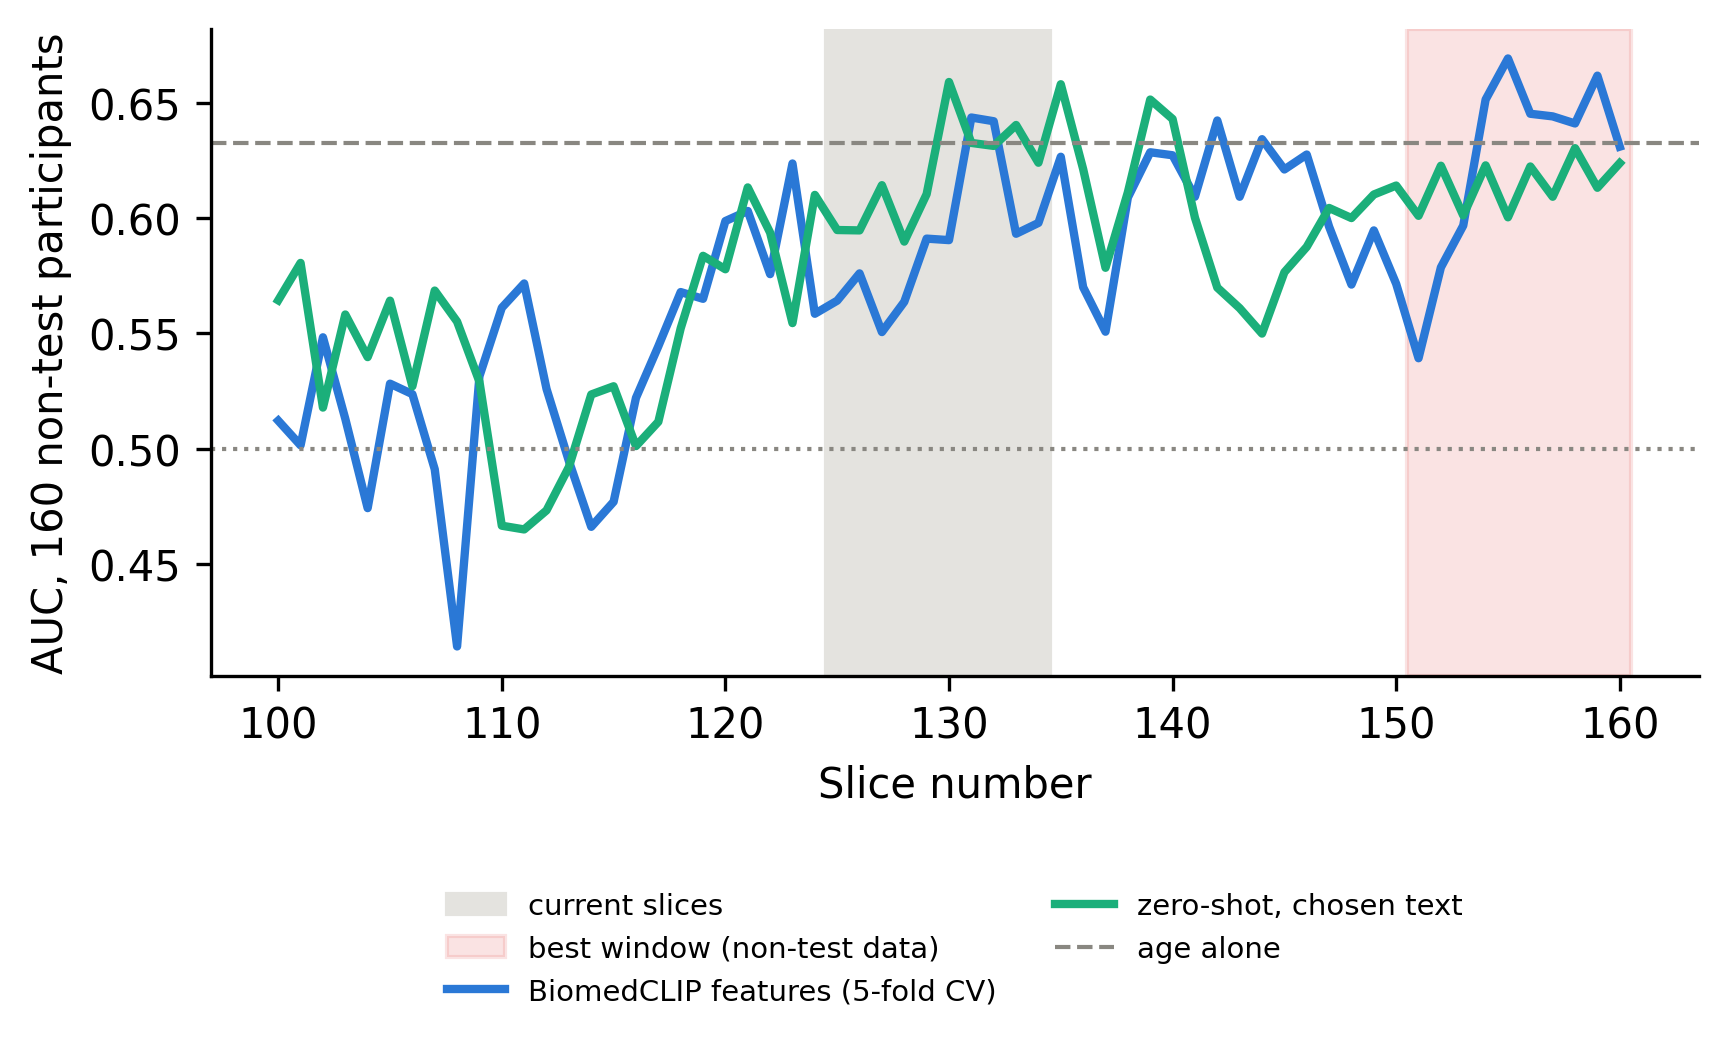

In [ ]:
!python /content/alz_ext/slice_positions.py /content/alz_ext/all_slices.csv {RESULTS} {CUR_FIRST} {CUR_LAST} 2>&1 | grep -v -i "warn\|pytree\|deprecat"
from IPython.display import Image
Image(f'{RESULTS}/figures/oasis1bin_slice_positions.png', width=650)

## 16. Choosing the slices and the text, and a cross-validated estimate



In [ ]:
%%writefile /content/alz_ext/select_and_estimate.py
import json, sys
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

BIOMEDCOOP = '/content/BiomedCoOp'
sys.path[:0] = [BIOMEDCOOP]
from open_clip.src.open_clip import create_model_from_pretrained, get_tokenizer

CSV, RESULTS, CUR_FIRST = sys.argv[1], sys.argv[2], int(sys.argv[3])
WINDOW, STEP = 10, 5
HUB = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, _ = create_model_from_pretrained(HUB)
tokenizer = get_tokenizer(HUB)
model.eval().to(device)
SCALE = model.logit_scale.exp().item()

df = pd.read_csv(CSV).reset_index(drop=True)
index = pd.read_csv(f'{RESULTS}/OASIS1_all_slice_index.csv')
assert (index.subject.values == df.subject.values).all() and (index.slice.values == df.slice.values).all(), \
    'the saved features do not match the slice list: run section 15 first'
feats = np.load(f'{RESULTS}/OASIS1_all_slice_features.npy')

NAME_PAIRS = {
    'original': ('no dementia', 'dementia'),
    'healthy_ad': ('healthy aging', "Alzheimer's disease"),
    'normal_atrophy': ('normal brain', 'atrophied brain'),
    'cn_dementia': ('cognitively normal', 'dementia'),
}
DESC_SETS = ['original', 'visible', 'detailed', 'mtl']
OLD = ['no dementia', 'dementia']
DESC = {t: json.load(open(f'/content/alz_ext/descriptions_{t}.json')) for t in DESC_SETS}


@torch.no_grad()
def prototypes(texts_per_class):
    # Same as the authors' zero-shot code: mean of the normalised text features.
    return torch.stack([F.normalize(F.normalize(model.encode_text(tokenizer(t).to(device)), dim=-1).mean(0), dim=0)
                        for t in texts_per_class]).cpu().numpy()


def p_dementia(W):
    logits = SCALE * feats @ W.T
    logits -= logits.max(1, keepdims=True)
    e = np.exp(logits)
    return e[:, 1] / e.sum(1)


P = {}
for key, names in NAME_PAIRS.items():
    for d in DESC_SETS:
        texts = [[x[:x.rstrip('.').rfind(o)] + n + '.' for x in DESC[d][o]] for o, n in zip(OLD, names)]
        P[(key, d)] = p_dementia(prototypes(texts))
P[('original', 'template')] = p_dementia(prototypes([[f'a photo of a {n}.'] for n in OLD]))
CANDIDATES = [c for c in P if c[1] != 'template']   # BiomedCoOp needs descriptions

STARTS = list(range(int(df.slice.min()), int(df.slice.max()) - WINDOW + 2, STEP))
in_window = {s: ((df.slice >= s) & (df.slice < s + WINDOW)).values for s in STARTS + [CUR_FIRST]}
people = df.drop_duplicates('subject').set_index('subject')[['part', 'y', 'age']]
y_slice = df.y.values


def slice_f1(rows, start, combo):
    m = rows & in_window[start]
    return f1_score(y_slice[m], (P[combo][m] > 0.5).astype(int), average='macro')


def choose(rows, starts, combos):
    return max(((s, c) for s in starts for c in combos), key=lambda sc: slice_f1(rows, *sc))


def person_prob(subjects, start, combo):
    m = df.subject.isin(subjects).values & in_window[start]
    return pd.Series(P[combo][m], index=df.subject.values[m]).groupby(level=0).mean().reindex(subjects)


def ci(y, pred, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    v = [f1_score(y[i], pred[i], average='macro') for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return 100 * np.percentile(v, 2.5), 100 * np.percentile(v, 97.5)


def line(name, y, pred):
    acc, f1 = 100 * (pred == y).mean(), 100 * f1_score(y, pred, average='macro')
    lo, hi = ci(y, pred)
    print(f'  {name:<46} accuracy {acc:5.1f}%  macro-F1 {f1:5.1f}% (95% CI {lo:.1f}-{hi:.1f})')
    return {'result': name, 'n': len(y), 'accuracy': round(acc, 2), 'macro_f1': round(f1, 2),
            'ci_low': round(lo, 2), 'ci_high': round(hi, 2)}


table = []

# 1. The choice for section 17, made on the 160 non-test participants
nontest = people.index[people.part != 'test']
rows_nt = df.subject.isin(nontest).values
start, combo = choose(rows_nt, STARTS, CANDIDATES)
names = NAME_PAIRS[combo[0]]
choice = {'names': list(names), 'desc': combo[1], 'folder': 'OASIS1SEL', 'first': start, 'last': start + WINDOW - 1}
json.dump(choice, open(f'{RESULTS}/OASIS1SEL_choice.json', 'w'), indent=1)
print(f'1. Chosen on the 160 non-test participants: slices {start}-{start + WINDOW - 1}, '
      f'names {names}, {combo[1]} descriptions (macro-F1 per slice there: {100 * slice_f1(rows_nt, start, combo):.1f}%)')

# 2. Test set (40 people), new choice next to the earlier setup
test = people.index[people.part == 'test']
y_test = people.y[test].values
old = json.load(open(f'{RESULTS}/OASIS1BIN_chosen_names.json'))
old_combo = (next(k for k, v in NAME_PAIRS.items() if list(v) == list(old['names'])), old['desc'])
print('\n2. Test set, per participant (40 people)')
for name, (s, c) in [('earlier: middle slices, one template', (CUR_FIRST, ('original', 'template'))),
                     ('earlier: middle slices, text chosen in section 9', (CUR_FIRST, old_combo)),
                     ('new: slices and text chosen above', (start, combo))]:
    table.append({'part': 'test (40)', **line(name, y_test, (person_prob(test, s, c).values > 0.5).astype(int))})

# 3. Cross-validated estimate on all 200 people (5 folds)
print('\n3. All 200 participants, 5-fold cross-validation (each person scored by a choice made without them)')
folds = list(StratifiedKFold(5, shuffle=True, random_state=0).split(people.index, people.y))
versions = {'A. middle slices, one template (no choice)': ([CUR_FIRST], [('original', 'template')]),
            'B. middle slices, text chosen': ([CUR_FIRST], CANDIDATES),
            'C. slices and text chosen': (STARTS, CANDIDATES)}
y_all = people.y.values
oof_c, chosen_c = None, []
for name, (starts, combos) in versions.items():
    prob = pd.Series(np.nan, index=people.index)
    for tr, te in folds:
        rows_tr = df.subject.isin(people.index[tr]).values
        s, c = choose(rows_tr, starts, combos)
        prob.iloc[te] = person_prob(people.index[te], s, c).values
        if name.startswith('C'):
            chosen_c.append((s, c))
    table.append({'part': 'all 200 (CV)', **line(name, y_all, (prob.values > 0.5).astype(int))})
    if name.startswith('C'):
        oof_c = prob

age_prob, both_prob = pd.Series(np.nan, index=people.index), pd.Series(np.nan, index=people.index)
for (tr, te), (s, c) in zip(folds, chosen_c):
    lr = LogisticRegression(class_weight='balanced').fit(people[['age']].iloc[tr], y_all[tr])
    age_prob.iloc[te] = lr.predict_proba(people[['age']].iloc[te])[:, 1]
    score_tr = person_prob(people.index[tr], s, c).values
    score_te = person_prob(people.index[te], s, c).values
    X_tr = np.c_[people.age.values[tr], score_tr]
    X_te = np.c_[people.age.values[te], score_te]
    lr2 = LogisticRegression(class_weight='balanced').fit(X_tr, y_all[tr])
    both_prob.iloc[te] = lr2.predict_proba(X_te)[:, 1]
table.append({'part': 'all 200 (CV)', **line('age only', y_all, (age_prob.values > 0.5).astype(int))})
table.append({'part': 'all 200 (CV)', **line('age + version C score', y_all, (both_prob.values > 0.5).astype(int))})
old70 = (people.age >= 70).values
print(f'\n   aged 70 and over ({old70.sum()} people; mean age: no dementia '
      f'{people.age[old70 & (y_all == 0)].mean():.1f}, dementia {people.age[old70 & (y_all == 1)].mean():.1f})')
table.append({'part': 'aged 70+ (CV)', **line('C. slices and text chosen', y_all[old70],
                                               (oof_c.values[old70] > 0.5).astype(int))})
print('\n   choices made in the 5 folds of version C:')
for s, c in chosen_c:
    print(f'     slices {s}-{s + WINDOW - 1}, {NAME_PAIRS[c[0]]}, {c[1]} descriptions')
pd.DataFrame(table).to_csv(f'{RESULTS}/OASIS1SEL_estimate.csv', index=False)

Writing /content/alz_ext/select_and_estimate.py


In [ ]:
!python /content/alz_ext/select_and_estimate.py /content/alz_ext/all_slices.csv {RESULTS} {CUR_FIRST} 2>&1 | grep -v -i "warn\|pytree\|deprecat"

1. Chosen on the 160 non-test participants: slices 130-139, names ('normal brain', 'atrophied brain'), mtl descriptions (macro-F1 per slice there: 62.6%)

2. Test set, per participant (40 people)
  earlier: middle slices, one template           accuracy  67.5%  macro-F1  62.2% (95% CI 45.1-77.2)
  earlier: middle slices, text chosen in section 9 accuracy  75.0%  macro-F1  74.4% (95% CI 59.1-87.3)
  new: slices and text chosen above              accuracy  62.5%  macro-F1  59.4% (95% CI 43.0-74.7)

3. All 200 participants, 5-fold cross-validation (each person scored by a choice made without them)
  A. middle slices, one template (no choice)     accuracy  54.5%  macro-F1  51.1% (95% CI 43.9-57.9)
  B. middle slices, text chosen                  accuracy  64.5%  macro-F1  63.5% (95% CI 56.7-69.7)
  C. slices and text chosen                      accuracy  63.0%  macro-F1  61.8% (95% CI 54.8-68.5)
  age only                                       accuracy  60.0%  macro-F1  59.6% (95% CI 52.9-

## 17. Two classes with the chosen slices and text



In [ ]:
# A new two-class dataset with the slices chosen in section 16: same 200
# participants and the same train/val/test parts, only the slices change.
SEL = json.load(open(f'{RESULTS}/OASIS1SEL_choice.json'))
OSEL = f"OASIS1SEL_{SEL['first']}-{SEL['last']}"      # results folder, named after the slices
sel_dir = f'{DATA}/OASIS1SEL'
shutil.rmtree(sel_dir, ignore_errors=True)            # rebuilt every session
chosen = allsl[(allsl.slice >= SEL['first']) & (allsl.slice <= SEL['last'])]
split_sel = {'train': [], 'val': [], 'test': []}
for _, r in chosen.iterrows():
    folder = ['no_dementia', 'dementia'][int(r.y)]
    rel = f'{folder}/{r.subject}_{r.slice:03d}.jpg'
    os.makedirs(f'{sel_dir}/images/{folder}', exist_ok=True)
    shutil.copy(r.file, f'{sel_dir}/images/{rel}')
    split_sel[r.part].append((rel, int(r.y), BIN_NAMES[int(r.y)]))
json.dump(split_sel, open(f'{sel_dir}/split_OASIS1SEL.json', 'w'), indent=1)

# K-shot samples kept on Drive, in a folder named after the slices.
keep = f'{OUTPUTS}/{OSEL}_fewshot_samples'
os.makedirs(keep, exist_ok=True)
os.symlink(keep, f'{sel_dir}/split_fewshot')
use_names(SEL['names'], SEL['desc'], folder='OASIS1SEL')
print(OSEL, '| names:', SEL['names'], '| descriptions:', SEL['desc'])
print('images:', {p: len(v) for p, v in split_sel.items()},
      '| participants:', chosen.groupby('part').subject.nunique().to_dict())

OASIS1SEL_130-139 | names: ['normal brain', 'atrophied brain'] | descriptions: mtl
images: {'train': 1200, 'val': 400, 'test': 400} | participants: {'test': 40, 'train': 120, 'val': 40}


In [ ]:
# Zero-shot on the test set with the chosen slices and text (no training).
use_names(SEL['names'], SEL['desc'], folder='OASIS1SEL')
run('ZeroshotBiomedCLIP', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/{OSEL}/zeroshot_named',
    eval_only=True, script=WRAPPER['named'])
run('ZeroshotBiomedCLIP2', DATASET_CFG['OASIS1BINR'], ZEROSHOT_CFG, f'{OUTPUTS}/{OSEL}/zeroshot_ensemble_named',
    eval_only=True, script=WRAPPER['named'])


OASIS1SEL_130-139/zeroshot_named
    * accuracy: 66.25%
    * macro_f1: 58.26%

OASIS1SEL_130-139/zeroshot_ensemble_named
    * accuracy: 65.75%
    * macro_f1: 63.88%


In [ ]:
# BiomedCoOp with strong text guidance (KneeXray weights, as in section 11).
use_names(SEL['names'], SEL['desc'], folder='OASIS1SEL')
for k in SHOTS:
    for seed in SEEDS:
        run('BiomedCoOp_BiomedCLIP', DATASET_CFG['OASIS1BINR'], STRONG_CFG,
            f'{OUTPUTS}/{OSEL}/biomedcoop_named_strong/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=BIOMEDCOOP_OPTS, script=WRAPPER['named'])


OASIS1SEL_130-139/biomedcoop_named_strong/shots_1/seed1
    * accuracy: 62.50%
    * macro_f1: 59.06%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_1/seed2
    * accuracy: 61.75%
    * macro_f1: 42.61%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_1/seed3
    * accuracy: 72.25%
    * macro_f1: 67.20%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_2/seed1
    * accuracy: 64.00%
    * macro_f1: 55.11%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_2/seed2
    * accuracy: 60.50%
    * macro_f1: 58.94%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_2/seed3
    * accuracy: 64.50%
    * macro_f1: 60.86%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_4/seed1
    * accuracy: 70.25%
    * macro_f1: 65.46%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_4/seed2
    * accuracy: 70.25%
    * macro_f1: 69.34%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_4/seed3
    * accuracy: 62.75%
    * macro_f1: 58.72%

OASIS1SEL_130-139/biomedcoop_named_strong/shots_8/seed1
    * accuracy: 

In [ ]:
# Zero-shot-initialised linear probe on the same K-shot images (needs the K-shot
# files written by the BiomedCoOp runs above).
!python /content/alz_ext/zs_linear_probe.py {DATA} {OUTPUTS} {RESULTS} OASIS1SEL {RESULTS}/OASIS1SEL_choice.json {OSEL} 2>&1 | grep -v -i "warn\|pytree\|deprecat\|Reading split"

text prototypes from: {'names': ['normal brain', 'atrophied brain'], 'desc': 'mtl', 'folder': 'OASIS1SEL', 'first': 130, 'last': 139}

zero-shot with the chosen text: validation macro-F1 74.0%, test macro-F1 63.9%
ZS-LP K=1 seed=1, lambda = 100: accuracy 58.8%  macro-F1 48.7%  | per participant: accuracy 55.0%  macro-F1 40.0%
ZS-LP K=1 seed=2, lambda = 100: accuracy 42.5%  macro-F1 39.4%  | per participant: accuracy 40.0%  macro-F1 34.1%
ZS-LP K=1 seed=3, lambda = 100: accuracy 37.2%  macro-F1 34.1%  | per participant: accuracy 37.5%  macro-F1 34.2%
ZS-LP K=2 seed=1, lambda = 100: accuracy 68.0%  macro-F1 62.6%  | per participant: accuracy 72.5%  macro-F1 68.0%
ZS-LP K=2 seed=2, lambda = 100: accuracy 55.5%  macro-F1 55.5%  | per participant: accuracy 55.0%  macro-F1 54.9%
ZS-LP K=2 seed=3, lambda = 100: accuracy 35.8%  macro-F1 35.4%  | per participant: accuracy 40.0%  macro-F1 39.8%
ZS-LP K=4 seed=1, lambda = 100: accuracy 71.0%  macro-F1 70.2%  | per participant: accuracy 70.0%  mac

In [ ]:
# CoOp with the same names, for comparison (no descriptions in training).
use_names(SEL['names'], SEL['desc'], folder='OASIS1SEL')
for k in SHOTS:
    for seed in SEEDS:
        run('CoOp_BiomedCLIP', DATASET_CFG['OASIS1BINR'], COOP_CFG,
            f'{OUTPUTS}/{OSEL}/coop_named/shots_{k}/seed{seed}',
            shots=k, seed=seed, opts=COOP_OPTS, script=WRAPPER['named'])


OASIS1SEL_130-139/coop_named/shots_1/seed1
    * accuracy: 53.00%
    * macro_f1: 37.75%

OASIS1SEL_130-139/coop_named/shots_1/seed2
    * accuracy: 31.50%
    * macro_f1: 31.47%

OASIS1SEL_130-139/coop_named/shots_1/seed3
    * accuracy: 33.50%
    * macro_f1: 33.42%

OASIS1SEL_130-139/coop_named/shots_2/seed1
    * accuracy: 65.75%
    * macro_f1: 60.89%

OASIS1SEL_130-139/coop_named/shots_2/seed2
    * accuracy: 49.75%
    * macro_f1: 49.32%

OASIS1SEL_130-139/coop_named/shots_2/seed3
    * accuracy: 32.50%
    * macro_f1: 32.36%

OASIS1SEL_130-139/coop_named/shots_4/seed1
    * accuracy: 74.50%
    * macro_f1: 73.87%

OASIS1SEL_130-139/coop_named/shots_4/seed2
    * accuracy: 48.00%
    * macro_f1: 47.81%

OASIS1SEL_130-139/coop_named/shots_4/seed3
    * accuracy: 36.00%
    * macro_f1: 35.48%

OASIS1SEL_130-139/coop_named/shots_8/seed1
    * accuracy: 53.25%
    * macro_f1: 44.21%

OASIS1SEL_130-139/coop_named/shots_8/seed2
    * accuracy: 71.75%
    * macro_f1: 71.74%

OASIS1SEL

## 18. Results

These cells only read the saved logs, so they can be run at any time, also while some runs are missing.

In [ ]:
# Names used in the tables and figures. Only the methods in the final
# comparison are listed; other folders on Drive (early test runs) are not included.
LABELS = {
    'zeroshot': 'Zero-shot, one template',
    'zeroshot_ensemble': 'Zero-shot, original descriptions',
    'zeroshot_ensemble_visible': 'Zero-shot, visible-anatomy descriptions',
    'linear_probe': 'Linear probe',
    'coop': 'CoOp',
    'biomedcoop': 'BiomedCoOp',
    'zeroshot_named': 'Zero-shot, one template, chosen names',
    'zeroshot_ensemble_named': 'Zero-shot, chosen names and descriptions',
    'coop_named': 'CoOp, chosen names',
    'biomedcoop_named': 'BiomedCoOp, chosen names and descriptions',
    'biomedcoop_named_strong': 'BiomedCoOp, chosen text, stronger text guidance',
    'zeroshot_text_combination': 'Zero-shot, combination of texts',
    'zs_linear_probe': 'Zero-shot-initialised linear probe',
}
fmt = lambda m, s: f'{m:.1f}' if np.isnan(s) else f'{m:.1f} ± {s:.1f}'


def baselines(split_file):
    """Accuracy and macro-F1 of always predicting the largest class, and macro-F1 of guessing."""
    test = json.load(open(split_file))['test']
    counts = np.bincount([l for _, l, _ in test])
    p = counts.max() / counts.sum()
    return 100 * p, 100 * (2 * p / (1 + p)) / len(counts)


def main_table(dataset, split_file=None):
    runs, summary = collect(dataset)
    summary = summary[summary.method.isin(LABELS)].copy()
    summary['method'] = pd.Categorical(summary.method, categories=list(LABELS), ordered=True)
    summary = summary.sort_values(['method', 'shots'])
    t = summary.assign(acc=[fmt(m, s) for m, s in zip(summary.accuracy_mean, summary.accuracy_std)],
                       f1=[fmt(m, s) for m, s in zip(summary.macro_f1_mean, summary.macro_f1_std)])
    t = t.pivot(index='method', columns='shots', values=['acc', 'f1']).dropna(how='all')
    t.index = [LABELS[m] for m in t.index]
    t.to_csv(f'{RESULTS}/{dataset}_main_table.csv')
    acc, f1 = baselines(split_file or f'{DATA}/{dataset}/split_{dataset}.json')
    print(f'{dataset}: always predicting the largest class gives accuracy {acc:.1f}%, macro-F1 {f1:.1f}%')
    return summary, t


summary3, table3 = main_table('OASIS1')
table3

OASIS1: always predicting the largest class gives accuracy 60.0%, macro-F1 25.0%


acc                                        \
shots                               0            1            2           4    
Zero-shot, one template           11.8          NaN          NaN         NaN   
Zero-shot, original descriptions  19.2          NaN          NaN         NaN   
Linear probe                       NaN  32.5 ± 22.6  40.8 ± 16.1  44.8 ± 2.6   
BiomedCoOp                         NaN  26.6 ± 13.6   15.1 ± 4.1  33.0 ± 8.0   

                                                             f1               \
shots                                      8           16    0            1    
Zero-shot, one template                   NaN         NaN  10.0          NaN   
Zero-shot, original descriptions          NaN         NaN  18.3          NaN   
Linear probe                      42.9 ± 17.6  43.4 ± 4.5   NaN  25.1 ± 11.7   
BiomedCoOp                         33.3 ± 8.3  20.5 ± 3.1   NaN   23.8 ± 9.2   

                                                                        \
shots                                      2           4            8    
Zero-shot, one template                   NaN         NaN          NaN   
Zero-shot, original descriptions          NaN         NaN          NaN   
Linear probe                      33.0 ± 11.2  37.1 ± 2.9  36.0 ± 14.8   
BiomedCoOp                         14.4 ± 5.9  26.9 ± 2.0   29.0 ± 6.4   

                                              
shots                                     16  
Zero-shot, one template                  NaN  
Zero-shot, original descriptions         NaN  
Linear probe                      37.0 ± 5.4  
BiomedCoOp                        21.2 ± 1.8

In [ ]:
summary2, table2 = main_table('OASIS1BIN')
table2

OASIS1BIN: always predicting the largest class gives accuracy 60.0%, macro-F1 37.5%


acc               \
shots                                              0            1    
Zero-shot, one template                          65.5          NaN   
Zero-shot, original descriptions                 47.8          NaN   
Zero-shot, visible-anatomy descriptions          43.0          NaN   
Linear probe                                      NaN   34.0 ± 1.8   
CoOp                                              NaN   39.2 ± 9.0   
BiomedCoOp                                        NaN  40.5 ± 10.5   
Zero-shot, one template, chosen names            69.0          NaN   
Zero-shot, chosen names and descriptions         73.2          NaN   
CoOp, chosen names                                NaN   39.7 ± 5.6   
BiomedCoOp, chosen names and descriptions         NaN   40.6 ± 6.2   
BiomedCoOp, chosen text, stronger text guidance   NaN   65.0 ± 7.3   
Zero-shot, combination of texts                  73.2          NaN   
Zero-shot-initialised linear probe                NaN   54.0 ± 6.1   

                                                                           \
shots                                                     2            4    
Zero-shot, one template                                  NaN          NaN   
Zero-shot, original descriptions                         NaN          NaN   
Zero-shot, visible-anatomy descriptions                  NaN          NaN   
Linear probe                                     42.8 ± 19.7  51.1 ± 21.6   
CoOp                                             44.1 ± 17.5  45.8 ± 16.3   
BiomedCoOp                                       43.2 ± 16.8  44.4 ± 14.0   
Zero-shot, one template, chosen names                    NaN          NaN   
Zero-shot, chosen names and descriptions                 NaN          NaN   
CoOp, chosen names                               48.0 ± 16.9  52.8 ± 15.4   
BiomedCoOp, chosen names and descriptions        48.5 ± 19.8  46.1 ± 11.1   
BiomedCoOp, chosen text, stronger text guidance   67.9 ± 3.2   69.7 ± 5.9   
Zero-shot, combination of texts                          NaN          NaN   
Zero-shot-initialised linear probe               58.2 ± 16.7  61.2 ± 18.5   

                                                                           \
shots                                                     8            16   
Zero-shot, one template                                  NaN          NaN   
Zero-shot, original descriptions                         NaN          NaN   
Zero-shot, visible-anatomy descriptions                  NaN          NaN   
Linear probe                                     49.8 ± 13.6   63.7 ± 5.0   
CoOp                                              46.8 ± 7.1  50.4 ± 17.9   
BiomedCoOp                                        41.8 ± 5.6  50.6 ± 16.1   
Zero-shot, one template, chosen names                    NaN          NaN   
Zero-shot, chosen names and descriptions                 NaN          NaN   
CoOp, chosen names                                55.2 ± 3.2  52.3 ± 11.3   
BiomedCoOp, chosen names and descriptions         55.2 ± 3.1  52.0 ± 15.0   
BiomedCoOp, chosen text, stronger text guidance   65.1 ± 4.9   70.6 ± 1.5   
Zero-shot, combination of texts                          NaN          NaN   
Zero-shot-initialised linear probe                72.2 ± 2.2   67.5 ± 6.7   

                                                   f1              \
shots                                              0           1    
Zero-shot, one template                          60.7         NaN   
Zero-shot, original descriptions                 42.9         NaN   
Zero-shot, visible-anatomy descriptions          34.5         NaN   
Linear probe                                      NaN  30.6 ± 0.3   
CoOp                                              NaN  32.1 ± 3.9   
BiomedCoOp                                        NaN  35.5 ± 9.2   
Zero-shot, one template, chosen names            62.2         NaN   
Zero-shot, chosen names and descriptions         72.7         NaN 

In [ ]:
# Two classes with the chosen slices and text (section 17).
summary_sel, table_sel = main_table(OSEL, split_file=f'{DATA}/OASIS1SEL/split_OASIS1SEL.json')
table_sel

OASIS1SEL_130-139: always predicting the largest class gives accuracy 60.0%, macro-F1 37.5%


acc               \
shots                                              0            1    
Zero-shot, one template, chosen names            66.2          NaN   
Zero-shot, chosen names and descriptions         65.8          NaN   
CoOp, chosen names                                NaN  39.3 ± 11.9   
BiomedCoOp, chosen text, stronger text guidance   NaN   65.5 ± 5.9   
Zero-shot-initialised linear probe                NaN  46.2 ± 11.2   

                                                                           \
shots                                                     2            4    
Zero-shot, one template, chosen names                    NaN          NaN   
Zero-shot, chosen names and descriptions                 NaN          NaN   
CoOp, chosen names                               49.3 ± 16.6  52.8 ± 19.7   
BiomedCoOp, chosen text, stronger text guidance   63.0 ± 2.2   67.8 ± 4.3   
Zero-shot-initialised linear probe               53.1 ± 16.3  59.3 ± 18.3   

                                                                          \
shots                                                     8           16   
Zero-shot, one template, chosen names                    NaN         NaN   
Zero-shot, chosen names and descriptions                 NaN         NaN   
CoOp, chosen names                               55.9 ± 14.7  50.0 ± 8.1   
BiomedCoOp, chosen text, stronger text guidance   60.0 ± 0.7  63.5 ± 6.4   
Zero-shot-initialised linear probe                64.2 ± 4.4  64.4 ± 4.5   

                                                   f1               \
shots                                              0            1    
Zero-shot, one template, chosen names            58.3          NaN   
Zero-shot, chosen names and descriptions         63.9          NaN   
CoOp, chosen names                                NaN   34.2 ± 3.2   
BiomedCoOp, chosen text, stronger text guidance   NaN  56.3 ± 12.5   
Zero-shot-initialised linear probe                NaN   40.8 ± 7.4   

                                                                           \
shots                                                     2            4    
Zero-shot, one template, chosen names                    NaN          NaN   
Zero-shot, chosen names and descriptions                 NaN          NaN   
CoOp, chosen names                               47.5 ± 14.3  52.4 ± 19.6   
BiomedCoOp, chosen text, stronger text guidance   58.3 ± 2.9   64.5 ± 5.4   
Zero-shot-initialised linear probe               51.2 ± 14.1  58.9 ± 18.1   

                                                                          
shots                                                     8           16  
Zero-shot, one template, chosen names                    NaN         NaN  
Zero-shot, chosen names and descriptions                 NaN         NaN  
CoOp, chosen names                               52.8 ± 16.4  49.0 ± 8.8  
BiomedCoOp, chosen text, stronger text guidance   58.2 ± 2.0  62.4 ± 5.1  
Zero-shot-initialised linear probe                61.6 ± 6.3  62.9 ± 6.0

In [ ]:
# Diagnostics with the full training set, both tasks.
diag = []
for dataset in ('OASIS1', 'OASIS1BIN'):
    for d in sorted(glob.glob(f'{OUTPUTS}/{dataset}_diagnostics_balanced/*')):
        r = read_result(d)
        if r:
            diag.append({'task': dataset, 'classifier': os.path.basename(d),
                         'accuracy': r['accuracy'], 'macro_f1': r['macro_f1']})
diag = pd.DataFrame(diag)
diag.to_csv(f'{RESULTS}/OASIS1_diagnostics.csv', index=False)
diag.pivot(index='classifier', columns='task', values=['accuracy', 'macro_f1'])

accuracy           macro_f1          
task                     OASIS1 OASIS1BIN   OASIS1 OASIS1BIN
classifier                                                  
biomedclip_1nn            50.50     59.50    32.54     56.19
biomedclip_logreg_full    56.00     66.00    42.96     64.80
raw_pixels_1nn            52.25     58.75    34.05     55.70
raw_pixels_logreg_full    59.25     71.50    43.75     69.91

In [ ]:
import matplotlib.pyplot as plt


INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e4e3df'
STYLE = {  # method: (label, colour, marker)
    'biomedcoop': ('BiomedCoOp', '#2a78d6', 'o'),
    'coop': ('CoOp', '#eb6834', 's'),
    'linear_probe': ('Linear probe', '#1baf7a', '^'),
    'biomedcoop_knee_settings': ('BiomedCoOp (KneeXray weights)', '#6250d6', 'D'),
}
plt.rcParams.update({
    'font.size': 9, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK2,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.titlecolor': INK, 'legend.frameon': False, 'savefig.dpi': 300,
    'savefig.bbox': 'tight'})


def shots_axis(ax):
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xscale('log', base=2)
    ax.set_xticks(SHOTS, [str(k) for k in SHOTS])
    ax.set_xlabel('Labelled images per class (K)')


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(f'{RESULTS}/figures/{name}.{ext}')
    plt.show()
STYLE = {  # method: (label, colour, marker)
    'biomedcoop': ('BiomedCoOp', '#2a78d6', 'o'),
    'coop': ('CoOp', '#eb6834', 's'),
    'linear_probe': ('Linear probe', '#1baf7a', '^'),
    'biomedcoop_named': ('BiomedCoOp, chosen names and descriptions', '#e34948', 'v'),
    'coop_named': ('CoOp, chosen names', '#6250d6', 'D'),
    'biomedcoop_named_strong': ('BiomedCoOp, chosen text, stronger guidance', '#b8860b', 'P'),
    'zs_linear_probe': ('Zero-shot-initialised linear probe', '#111111', 'X'),
}

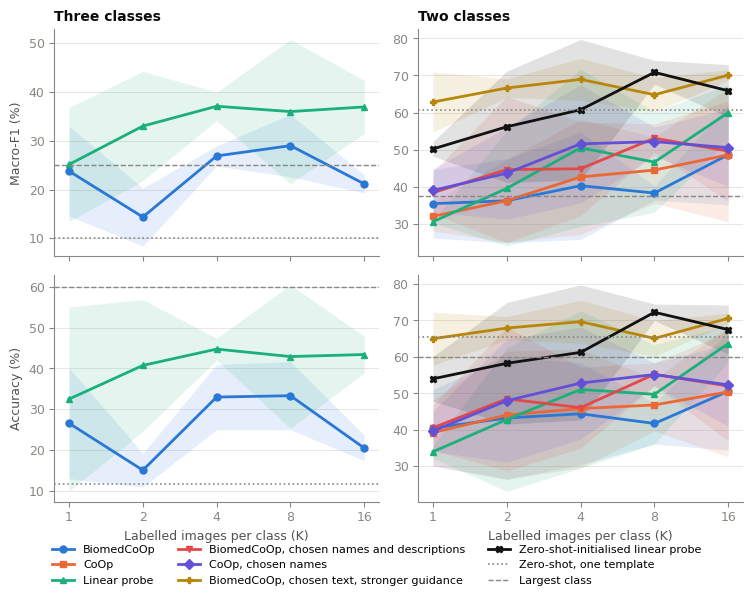

In [ ]:
# Macro-F1 and accuracy against K, for both tasks. Grey lines: zero-shot with
# one template, and always predicting the largest class.
fig, axes = plt.subplots(2, 2, figsize=(7.6, 5.6), sharex=True)
for col, (dataset, summary, title) in enumerate([('OASIS1', summary3, 'Three classes'),
                                                 ('OASIS1BIN', summary2, 'Two classes')]):
    maj_acc, maj_f1 = baselines(f'{DATA}/{dataset}/split_{dataset}.json')
    for row, (metric, ylabel, maj) in enumerate([('macro_f1', 'Macro-F1 (%)', maj_f1),
                                                ('accuracy', 'Accuracy (%)', maj_acc)]):
        ax = axes[row, col]
        for method, (label, colour, marker) in STYLE.items():
            d = summary[(summary.method == method) & (summary.shots > 0)]
            if d.empty:
                continue
            mean, std = d[f'{metric}_mean'].values, d[f'{metric}_std'].fillna(0).values
            ax.plot(d.shots, mean, color=colour, marker=marker, markersize=5, linewidth=2, label=label)
            ax.fill_between(d.shots, mean - std, mean + std, color=colour, alpha=0.12, linewidth=0)
        z = summary[summary.method == 'zeroshot']
        if not z.empty:
            ax.axhline(z[f'{metric}_mean'].iloc[0], color=MUTED, linestyle=':', linewidth=1.2,
                       label='Zero-shot, one template')
        ax.axhline(maj, color=MUTED, linestyle='--', linewidth=1.0, label='Largest class')
        shots_axis(ax)
        if row == 0:
            ax.set_xlabel('')
            ax.set_title(title, loc='left')
        if col == 0:
            ax.set_ylabel(ylabel)
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.07), fontsize=8)
fig.tight_layout()
save(fig, 'oasis1_shots')

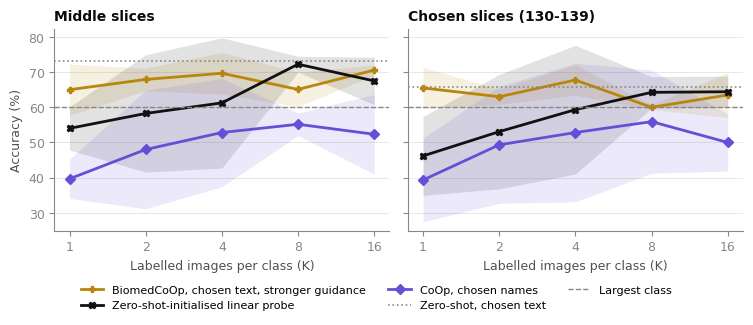

In [ ]:
# Section 17 results against K, next to the earlier middle slices.
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9), sharey=True)
for ax, (summary, title) in zip(axes, [(summary2, 'Middle slices'), (summary_sel, f'Chosen slices ({OSEL[10:]})')]):
    for method in ['biomedcoop_named_strong', 'zs_linear_probe', 'coop_named']:
        d = summary[(summary.method == method) & (summary.shots > 0)]
        if d.empty:
            continue
        label, colour, marker = STYLE[method]
        mean, std = d.accuracy_mean.values, d.accuracy_std.fillna(0).values
        ax.plot(d.shots, mean, color=colour, marker=marker, markersize=5, linewidth=2, label=label)
        ax.fill_between(d.shots, mean - std, mean + std, color=colour, alpha=0.12, linewidth=0)
    for zs, ls in [('zeroshot_ensemble_named', ':')]:
        z = summary[summary.method == zs]
        if not z.empty:
            ax.axhline(z.accuracy_mean.iloc[0], color=MUTED, linestyle=ls, linewidth=1.2, label='Zero-shot, chosen text')
    ax.axhline(60, color=MUTED, linestyle='--', linewidth=1.0, label='Largest class')
    shots_axis(ax)
    ax.set_title(title, loc='left')
axes[0].set_ylabel('Accuracy (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.12), fontsize=8)
fig.tight_layout()
save(fig, 'oasis1sel_vs_middle')

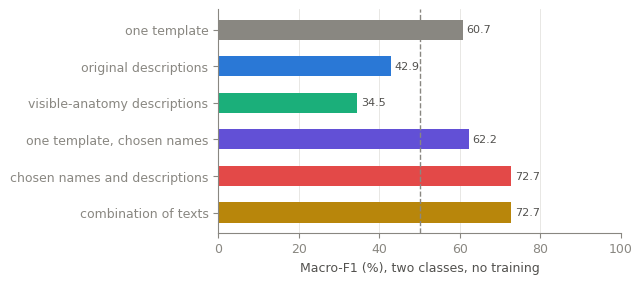

In [ ]:
# Effect of the text alone: zero-shot results with each kind of prompt, two classes.
zs = summary2[summary2.method.isin(['zeroshot', 'zeroshot_ensemble', 'zeroshot_ensemble_visible',
                                    'zeroshot_named', 'zeroshot_ensemble_named', 'zeroshot_text_combination'])]
fig, ax = plt.subplots(figsize=(5.2, 2.9))
y = np.arange(len(zs))
ax.barh(y, zs.macro_f1_mean, color=['#898781', '#2a78d6', '#1baf7a', '#6250d6', '#e34948', '#b8860b'][:len(zs)], height=0.55)
for yi, v in zip(y, zs.macro_f1_mean):
    ax.text(v + 1, yi, f'{v:.1f}', va='center', fontsize=8, color=INK2)
ax.set_yticks(y, [LABELS[m].replace('Zero-shot, ', '') for m in zs.method])
ax.axvline(50, color=MUTED, linestyle='--', linewidth=1.0)
ax.set_xlim(0, 100)
ax.set_xlabel('Macro-F1 (%), two classes, no training')
ax.invert_yaxis()
ax.grid(axis='x', color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
save(fig, 'oasis1bin_zeroshot_prompts')

In [ ]:
# Software versions, for the report.
import importlib.metadata as im
import platform, torch
print('python', platform.python_version(), '| GPU:', torch.cuda.get_device_name(0))
for p in ['torch', 'torchvision', 'open_clip_torch', 'transformers', 'timm', 'scikit-learn', 'numpy', 'pandas']:
    try:
        print(p, im.version(p))
    except im.PackageNotFoundError:
        print(p, 'not installed')

python 3.13.16 | GPU: Tesla T4
torch 2.14.1+cu130
torchvision 0.29.1+cu130
open_clip_torch 2.23.0
transformers 4.35.2
timm 1.0.31
scikit-learn 1.6.1
numpy 2.4.6
pandas 2.2.3
